# Live hard coral cover with the 768 px model (cd275k, KL w=0.5): per source, per biogeographic region, and across all test data

Copy of `Coral_Cover_Live_KL05_Regions.ipynb` with a different model and prediction resolution. That notebook
follows `Coral_Cover_GT_vs_Base_10src_taxv2.ipynb`, with three changes:
- **Model**: `cbm_cd275000_res768` at step 50k (`/data/vision/beery/scratch/sauder/mermaid-segmentation-final/nbs/model_checkpoints/cbm_cd275000_res768/model_step50000`), a ViT-L DPT LoRA CBM trained at 768 px with
  KL w=0.5 on the taxv2 concept table (identical CSV and 703-concept map). **Predictions are made at 768 × 768 px**
  (the original notebook used 256 px). Its test split is the dedup test split, so none of the 33 sources were
  trained on.
- **Target is live hard coral**: `order = scleractinia` **and** `live = True`.
  - Ground truth: a point counts only if its CoralNet class maps to scleractinia with `live` positive. Dead coral
    (`live` negative) is not hard coral. In the viable sources every scleractinia label has `live` given.
  - Model: the order argmax is scleractinia **and** P(live) > 0.5, at the points and for every pixel.
- **All viable test sources** (33 instead of 10), then pooled into **biogeographic regions**, then **all test data**.
  In a region or in "all test", a survey of n images draws them at random from all images of the group's sources.

**Three cover estimates per image.**
- **Ground truth**: share of the annotated points that are live hard coral.
- **Model at the points**: share of the same points predicted live hard coral (difference = model error).
- **Model, all pixels**: share of all pixels predicted live hard coral (needs no annotation).

**Viable sources.** Test sources (dedup split) with ≥ 100 images, ≥ 5% live hard coral cover, and ≤ 5% of points on
coral-like labels with no order in the concept table. Those labels would be scored as not hard coral, so the ground
truth would be too low. Because dead coral no longer counts, the sources excluded before for that reason (2615, 2616,
4721, 7049) are back in.

**Regions.** Marine Ecoregions of the World realms (Spalding et al. 2007), assigned from each source's name,
description and coordinates. The coordinates are placeholders for 2655 (NSW), 6551 (UH Hilo, assumed Hawaiʻi) and
6702 (Veracruz reef system), and have the wrong sign for 4280 (assumed Hawaiʻi).

Inputs:
```
python scripts/coral_cover_eligibility.py --split test \
    --concept-id2name eval_out/scratch100k_hier/cbm_scratch100k_kl_w0.5_taxv2/concept_id2name.json \
    --class-to-concepts nbs/model_checkpoints/cbm_scratch100k_kl_w0.5_taxv2/class_to_concepts.csv \
    --out eval_out/coral_cover/test_sources_cover_eligibility_taxv2.csv
python scripts/coral_cover_predict.py --split test --sources <the 33 sources> \
    --checkpoint /data/vision/beery/scratch/sauder/mermaid-segmentation-final/nbs/model_checkpoints/cbm_cd275000_res768/model_step50000 \
    --concept-id2name eval_out/scratch100k_hier/cbm_scratch100k_kl_w0.5_taxv2/concept_id2name.json \
    --class-to-concepts nbs/model_checkpoints/cbm_scratch100k_kl_w0.5_taxv2/class_to_concepts.csv \
    --resolution 768 --batch-size 8 \
    --out eval_out/coral_cover/coralnet_test_pred_cd275k_res768_step50000_viable.parquet \
    --points-out eval_out/coral_cover/coralnet_test_pred_cd275k_res768_step50000_viable_points.parquet
```

**Method.** A group's cover is the mean of its per-image cover; 95% CIs come from an image-level bootstrap. Bias =
model − ground truth, with a paired bootstrap CI (the same image resamples for every estimate). For sample size, the
same `R` random sets of n images (without replacement, seed `SEED`) are scored with all three estimates. Each is
compared with the group's **ground-truth** cover over all its images.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

REPO = Path("..").resolve() if Path("../eval_out").exists() else Path(".").resolve()
CC = REPO / "eval_out/coral_cover"
STEM = "coralnet_test_pred_cd275k_res768_step50000_viable"
PRED, POINTS = CC / f"{STEM}.parquet", CC / f"{STEM}_points.parquet"
ELIG = CC / "test_sources_cover_eligibility_taxv2.csv"
META = REPO / "data/coralnet_dedup/coralnet_source_metadata.csv"
B = 10_000
R = 2_000
R_CI, B_CI = 200, 1_000  # surveys whose own bootstrap CI is checked, and its iterations
N_GRID = [10, 25, 50, 100, 250, 500, 1000, 2500, 5000, 10_000, 25_000]
TOLS = (0.05, 0.02)
SEED = 0
MIN_IMAGES, MIN_COVER, MAX_CORAL_NO_ORDER = 100, 0.05, 0.05

# MEOW realm -> sources (see the introduction for sources whose coordinates are wrong)
REGIONS = {
    "Tropical Atlantic": [1304, 1642, 4091, 5181, 6494, 6702, 7049],
    "Western Indo-Pacific": [2615, 2616, 4721, 4342, 4816],
    "Central Indo-Pacific": [290, 1776, 3350, 6673, 2052, 2955, 3606, 6391, 4957, 7116],
    "Eastern Indo-Pacific": [1990, 2682, 3357, 4280, 6551, 6405, 3697, 5227],
    "Temperate Australasia": [2311, 2655, 3656],
}
REGION_OF = {s: r for r, ss in REGIONS.items() for s in ss}
REGION_COLOR = dict(zip(REGIONS, ["#2a78d6", "#d4a106", "#1baf7a", "#eb6834", "#8a4fd0"]))
ESTIMATES = {  # key -> (label, colour, marker)
    "truth": ("ground truth (points)", "#2a78d6", "o"),
    "model_points": ("model at the points", "#eb6834", "s"),
    "model_dense": ("model, all pixels", "#1baf7a", "^"),
}
INK, MUTED, GRID, BAND, SURFACE = "#1c1c1a", "#6b6a64", "#e4e3df", "#ebeae6", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlecolor": INK, "axes.titlesize": 10, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.frameon": False, "figure.dpi": 100,
})
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.max_rows", 100)
rng = np.random.default_rng(SEED)
pct = mticker.PercentFormatter(1.0, decimals=0)

images = pd.read_parquet(PRED).sort_values(["source_id", "image_id"]).reset_index(drop=True)
images["truth"] = images.n_live_gt / images.n_points
images["model_points"] = images.n_live_pred / images.n_points
images["model_dense"] = images.dense_live
images["region"] = images.source_id.map(REGION_OF)
assert images.region.notna().all() and set(images.source_id) == set(REGION_OF), "sources and REGIONS differ"
pts = pd.read_parquet(POINTS)
pts["live_gt"] = (pts.gt_code == 2) & (pts.gt_live_code == 2)  # live hard coral in the annotations
pts["live_pred"] = pts.pred_live_hard
pts["region"] = pts.source_id.map(REGION_OF)

# Sources ordered by region, then by ground-truth cover within the region.
gt_cover = images.groupby("source_id").truth.mean()
SOURCES = [s for r in REGIONS for s in gt_cover[REGIONS[r]].sort_values().index]
GROUPS = {
    "source": {s: [s] for s in SOURCES},
    "region": REGIONS,
    "all": {"all test": SOURCES},
}
X = {lvl: {g: images.loc[images.source_id.isin(ss), list(ESTIMATES)].to_numpy().T for g, ss in grp.items()}
     for lvl, grp in GROUPS.items()}  # level -> group -> (3, images)


def legend(fig, keys=ESTIMATES, extra=(), ncol=None, y=1.0):
    handles = [Line2D([], [], color=ESTIMATES[k][1], marker=ESTIMATES[k][2], lw=2, label=ESTIMATES[k][0]) for k in keys]
    handles += list(extra)
    fig.legend(handles=handles, loc="upper right", ncol=ncol or len(handles), fontsize=9, bbox_to_anchor=(1, y))


print(f"{len(SOURCES)} sources in {len(REGIONS)} regions, {len(images):,} images, {len(pts):,} points")

33 sources in 5 regions, 34,138 images, 813,481 points


## 1. Viable sources and regions
How many test sources pass each criterion, and the 33 that are used, by region.

In [2]:
elig = pd.read_csv(ELIG).set_index("source_id")
ok_img, ok_cov, ok_lab = (elig.images >= MIN_IMAGES), (elig.live_cover >= MIN_COVER), (elig.coral_no_order_frac <= MAX_CORAL_NO_ORDER)
print(f"{len(elig)} test sources; ≥{MIN_IMAGES} images: {ok_img.sum()}; and ≥{MIN_COVER:.0%} live cover: "
      f"{(ok_img & ok_cov).sum()}; and ≤{MAX_CORAL_NO_ORDER:.0%} coral labels without order: {(ok_img & ok_cov & ok_lab).sum()}")
assert set(elig.index[ok_img & ok_cov & ok_lab]) == set(SOURCES), "eligibility table and predictions differ"
dropped = elig[ok_img & ok_cov & ~ok_lab]
display(dropped[["name", "images", "live_cover", "coral_no_order_frac", "top_coral_no_order"]]
        .style.format({"live_cover": "{:.1%}", "coral_no_order_frac": "{:.1%}"})
        .set_caption("Enough images and cover, dropped: coral-like labels with no order (scored as not hard coral)"))

src = elig.loc[SOURCES, ["name", "latitude", "longitude", "images", "points_per_image", "cover", "live_cover", "dead_hard_frac"]]
src.insert(0, "region", [REGION_OF[s] for s in SOURCES])
src["model images"] = images.groupby("source_id").size().loc[SOURCES]
src.style.format({"cover": "{:.1%}", "live_cover": "{:.1%}", "dead_hard_frac": "{:.0%}", "latitude": "{:.2f}",
                  "longitude": "{:.2f}"}).set_caption(
    "Viable sources. cover: scleractinia incl. dead; live_cover: the target; dead_hard_frac: share of scleractinia that is dead")

144 test sources; ≥100 images: 61; and ≥5% live cover: 37; and ≤5% coral labels without order: 33


,name,images,live_cover,coral_no_order_frac,top_coral_no_order
source_id,,,,,
1826,(historic image set) Norfolk Island,211,17.8%,5.9%,"encrusting coral (pale) (568), pale other acropora (306), acropora branching (pale) (263)"
3241,PUR PROJET PERJARAKAN,211,8.7%,21.2%,"bra: acropora branching (687), mase: porites (331), pocillopora species (39)"
6324,CoralD,325,30.3%,9.5%,"cyanobacteria smothering live coral (570), other branching corals (199)"
7663,Wawama,200,13.6%,12.7%,"montipora monasteriata (380), leptoseris foliosa (134), montipora hoffmeisteri (64)"


,region,name,latitude,longitude,images,points_per_image,cover,live_cover,dead_hard_frac,model images
source_id,,,,,,,,,,
5181,Tropical Atlantic,MarineGEO RLS,18.37,-68.79,1061,25,10.4%,10.4%,0%,1061
4091,Tropical Atlantic,Little Cayman MarineGEO,19.69,-80.07,463,40,11.2%,11.2%,0%,463
6702,Tropical Atlantic,IDcobertura,18.00,95.00,1368,13,11.5%,11.5%,0%,1368
6494,Tropical Atlantic,Cayos_cochinos,15.96,-86.47,133,30,17.4%,15.8%,9%,133
1304,Tropical Atlantic,Reef restoration SBR,12.60,-81.70,111,25,17.0%,17.0%,0%,111
7049,Tropical Atlantic,IDEA Grant 2,12.20,-69.26,1168,64,52.9%,20.3%,62%,1168
1642,Tropical Atlantic,SFS TIBS,9.30,-82.27,146,25,22.8%,22.8%,0%,146
4816,Western Indo-Pacific,LATHAM ISLAND BES,-6.91,39.91,635,25,6.1%,6.1%,0%,635
4721,Western Indo-Pacific,Thuwal Bleaching Conditions,22.34,39.02,2909,50,9.0%,7.1%,20%,2909


### Region composition
In a region, images are sampled from the pooled images of its sources, so large sources weigh more. The last
column gives the share of the region's images that come from its largest source.

In [3]:
comp = pd.DataFrame({
    r: {"sources": len(ss), "images": int(src.loc[ss, "model images"].sum()),
        "points / image (median)": int(images.loc[images.region == r, "n_points"].median()),
        "GT live cover range across sources": f"{gt_cover[ss].min():.0%}–{gt_cover[ss].max():.0%}",
        "largest source": f"{src.loc[ss, 'model images'].idxmax()} ({src.loc[ss, 'model images'].max() / src.loc[ss, 'model images'].sum():.0%})"}
    for r, ss in REGIONS.items()}).T
comp.loc["all test"] = [len(SOURCES), len(images), int(images.n_points.median()),
                        f"{gt_cover.min():.0%}–{gt_cover.max():.0%}",
                        f"{src['model images'].idxmax()} ({src['model images'].max() / len(images):.0%})"]
comp

,sources,images,points / image (median),GT live cover range across sources,largest source
Tropical Atlantic,7,4450,25,10%–23%,6702 (31%)
Western Indo-Pacific,5,8828,20,6%–25%,4721 (33%)
Central Indo-Pacific,10,14594,5,8%–38%,4957 (62%)
Eastern Indo-Pacific,8,5657,25,7%–24%,6405 (24%)
Temperate Australasia,3,609,25,6%–24%,3656 (59%)
all test,33,34138,20,6%–38%,4957 (26%)


Helpers used at every level (source, region, all). `summarize` gives cover and bias with paired bootstrap CIs, and
precision and recall of live hard coral at the points. `survey_error` gives the error that 95% of random n-image
surveys stay within, measured against the group's ground-truth cover over all its images. `images_needed` gives the
smallest n at which that error is ≤ ±5 / ±2 pp. `ci_coverage` gives how often a 100-image survey's own 95% bootstrap CI
contains that cover.

In [4]:
def boot_means(x, n_boot, max_elems=4_000_000):
    """(3, n_boot) bootstrap means of the columns of x, the same resamples for every row (paired)."""
    n = x.shape[1]
    step = max(1, max_elems // n)
    out = [x[:, rng.integers(0, n, size=(min(step, n_boot - i), n))].mean(axis=2) for i in range(0, n_boot, step)]
    return np.concatenate(out, axis=1)


def summarize(level):
    rows = []
    for g, ss in GROUPS[level].items():
        x = X[level][g]
        boot = boot_means(x, B)
        p = pts[pts.source_id.isin(ss)]
        tp, fp, fn = (p.live_gt & p.live_pred).sum(), (~p.live_gt & p.live_pred).sum(), (p.live_gt & ~p.live_pred).sum()
        row = {"group": g, "sources": len(ss), "images": x.shape[1],
               "points/image": int(np.median(images.loc[images.source_id.isin(ss), "n_points"]))}
        for i, key in enumerate(ESTIMATES):
            row[key] = x[i].mean()
            row[f"{key} lo"], row[f"{key} hi"] = np.quantile(boot[i], [0.025, 0.975])
            if key != "truth":
                row[f"bias {key}"] = x[i].mean() - x[0].mean()
                row[f"bias {key} lo"], row[f"bias {key} hi"] = np.quantile(boot[i] - boot[0], [0.025, 0.975])
                row[f"r {key}"] = np.corrcoef(x[0], x[i])[0, 1]
        row.update(precision=tp / (tp + fp), recall=tp / (tp + fn))
        rows.append(row)
    return pd.DataFrame(rows).set_index("group")


def show_summary(s):
    ci = lambda r, k: f"{100 * r[k]:+.1f} [{100 * r[k + ' lo']:+.1f}, {100 * r[k + ' hi']:+.1f}]"
    out = pd.DataFrame({
        "images": s.images, "points/image": s["points/image"],
        "ground truth": [f"{r.truth:.1%} [{r['truth lo']:.1%}, {r['truth hi']:.1%}]" for _, r in s.iterrows()],
        "model at the points": [f"{r.model_points:.1%}" for _, r in s.iterrows()],
        "bias, points (pp)": [ci(r, "bias model_points") for _, r in s.iterrows()],
        "model, all pixels": [f"{r.model_dense:.1%}" for _, r in s.iterrows()],
        "bias, all pixels (pp)": [ci(r, "bias model_dense") for _, r in s.iterrows()],
        "precision": s.precision.round(2), "recall": s.recall.round(2),
        "r per image (points)": s["r model_points"].round(2), "r per image (pixels)": s["r model_dense"].round(2),
    })
    if (s.sources > 1).any():
        out.insert(0, "sources", s.sources)
    return out


def allocate(n, sizes):
    """Split n images as evenly as possible over sources of the given sizes, without exceeding any source (water-filling;
    leftover single images go to the sources with the most images left). Nested: allocate(n + 1) ≥ allocate(n)."""
    sizes = np.asarray(sizes)
    a = np.zeros(len(sizes), dtype=int)
    while (left := n - a.sum()) > 0:
        room = sizes - a
        open_ = np.flatnonzero(room > 0)
        share = left // len(open_)
        if share == 0:
            a[open_[np.argsort(-room[open_], kind="stable")[:left]]] += 1
        else:
            a[open_] += np.minimum(share, room[open_])
    return a


def survey_errors(x, ns, n_sets, strata=None, gen=None, max_elems=4_000_000):
    """(3, n_sets, len(ns)): signed error (survey estimate − ground-truth target) of n_sets random n-image surveys,
    all without replacement, with prefix means via cumsum (a survey of n images is nested in the one of n + 1).
    strata=None: each set is a random permutation of all images and its first n images are the survey; estimate and
    target are means over images. strata = list of index arrays, one per source: each source is permuted on its own and
    contributes its first allocate(n, sizes) images; estimate and target are the mean of the per-source means, so every
    source counts 1/S. Needs n ≥ S."""
    gen = rng if gen is None else gen
    n_all = x.shape[1]
    ns = np.asarray(ns)
    if strata is not None:
        alloc = np.array([allocate(n, [len(ix) for ix in strata]) for n in ns])  # (len(ns), S)
        assert (alloc > 0).all(), "every source needs at least one image: n ≥ number of sources"
        target = np.mean([x[0, ix].mean() for ix in strata])
    step = max(1, max_elems // n_all)
    errs = []
    for i in range(0, n_sets, step):
        k = min(step, n_sets - i)
        if strata is None:
            cs = np.cumsum(x[:, np.argsort(gen.random((k, n_all)), axis=1)], axis=2)  # (3, sets, n_all)
            errs.append(cs[:, :, ns - 1] / ns - x[0].mean())
        else:
            est = np.zeros((3, k, len(ns)))
            for j, ix in enumerate(strata):
                cs = np.cumsum(x[:, ix][:, np.argsort(gen.random((k, len(ix))), axis=1)], axis=2)  # (3, sets, N_s)
                est += cs[:, :, alloc[:, j] - 1] / alloc[:, j]
            errs.append(est / len(strata) - target)
    return np.concatenate(errs, axis=1)


def survey_error(x, ns, n_sets, q=0.95):
    """(3, len(ns)): q-quantile over n_sets random n-image surveys of |survey mean − ground-truth mean of all images|."""
    return np.quantile(np.abs(survey_errors(x, ns, n_sets)), q, axis=1)


# Error summaries over the random surveys: column name -> (y-axis label, (3, sets, ns) errors -> (3, ns)).
ERROR_STATS = {
    "error vs GT (95%)": ("95% of surveys within", lambda e: np.quantile(np.abs(e), 0.95, axis=1)),
    "mean |error|": ("mean |error| over surveys", lambda e: np.abs(e).mean(axis=1)),
    "RMSE": ("RMSE over surveys", lambda e: np.sqrt((e ** 2).mean(axis=1))),
}


def convergence(level, by_source=False):
    """Survey error statistics per group, estimate and n. by_source=True: every source in a group counts equally
    (stratified surveys: n images spread evenly over the sources, estimate = mean of per-source means, target = mean of
    the sources' ground-truth covers; n starts at the number of sources). It uses its own generator, so the global rng
    stream is the same with or without it."""
    gen = np.random.default_rng(SEED + 1) if by_source else rng
    rows = []
    for g, x in X[level].items():
        n_all = x.shape[1]
        if by_source:
            src = images.loc[images.source_id.isin(GROUPS[level][g]), "source_id"].to_numpy()
            strata = [np.flatnonzero(src == s) for s in GROUPS[level][g]]
            target = np.mean([x[0, ix].mean() for ix in strata])
        else:
            strata, target = None, x[0].mean()
        n_min = len(strata) if by_source else 1
        ns = [m for m in N_GRID if n_min <= m < n_all] + [n_all]
        e = survey_errors(x, ns, R, strata=strata, gen=gen)  # the same surveys for every statistic
        stats = {col: f(e) for col, (_, f) in ERROR_STATS.items()}  # col -> (3, len(ns))
        for i, key in enumerate(ESTIMATES):
            rows += [{"group": g, "n": n, "estimate": key, "target": target, **{col: v[i, j] for col, v in stats.items()}}
                     for j, n in enumerate(ns)]
    return pd.DataFrame(rows)


def plot_convergence_compare(convs, level, ncols=None, ylim=(0.1, 30), panel_w=3.4, panel_h=2.8):
    """One row per error statistic, one column per group; each conv in convs = {label: (conv, linestyle)} is drawn
    with its own line style, colours by estimate."""
    groups = list(X[level])
    ncols = ncols or len(groups)
    fig, axes = plt.subplots(len(ERROR_STATS), ncols, figsize=(panel_w * ncols, panel_h * len(ERROR_STATS) + 0.7),
                             sharey=True, squeeze=False)
    for r, (stat, (ylabel, _)) in enumerate(ERROR_STATS.items()):
        for ax, g in zip(axes[r], groups):
            for conv, ls in convs.values():
                for key, (_, color, marker) in ESTIMATES.items():
                    c = conv[(conv.group == g) & (conv.estimate == key)]
                    if key == "truth":
                        c = c[c[stat] > 1e-9]
                    ax.plot(c.n, 100 * c[stat], color=color, ls=ls, marker=marker, ms=3.5, mec="white", lw=1.8)
            for lv in (5, 2, 1):
                ax.axhline(lv, color=GRID, lw=1.2, zorder=0)
            ax.set_xscale("log")
            ax.set_yscale("log")
            ax.set_ylim(*ylim)
            ax.yaxis.set_major_locator(mticker.FixedLocator([0.2, 0.5, 1, 2, 5, 10, 20]))
            ax.yaxis.set_minor_locator(mticker.NullLocator())
            pm = "±" if stat == "error vs GT (95%)" else ""
            ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _, pm=pm: f"{pm}{v:g} pp"))
            ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{int(v):,}"))
            if r == 0:
                gts = ", ".join(f"{conv.loc[conv.group == g, 'target'].iloc[0]:.0%}" for conv, _ in convs.values())
                ax.set_title(f"{g}\nGT {gts}", fontsize=9, color=REGION_COLOR.get(REGION_OF.get(g, g), INK))
        axes[r, 0].set_ylabel(ylabel)
    for ax in axes[-1]:
        ax.set_xlabel("images sampled (n)")
    extra = [Line2D([], [], color=MUTED, ls=ls, lw=1.8, label=label) for label, (_, ls) in convs.items()]
    legend(fig, extra=extra, ncol=len(ESTIMATES) + len(extra))
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.7 / (panel_h * len(ERROR_STATS) + 0.7)))
    plt.show()


def images_needed(level, n_sets=1_000, n_ci=100):
    rows = []
    for g, x in X[level].items():
        n_all = x.shape[1]
        ns = np.unique(np.round(np.geomspace(5, n_all, 60)).astype(int))
        err = survey_error(x, ns, n_sets)
        row = {"group": g, "images": n_all}
        for t in TOLS:
            for i, k in enumerate(ESTIMATES):
                hit = np.flatnonzero(err[i] <= t)
                row[(f"±{t:.0%}: images needed", ESTIMATES[k][0])] = int(ns[hit[0]]) if len(hit) else "never"
        gt = x[0].mean()
        sets = np.argsort(rng.random((R_CI, n_all)), axis=1)[:, :n_ci]
        for i, k in enumerate(ESTIMATES):
            xs = x[i][sets]  # (R_CI, n_ci)
            means = np.take_along_axis(xs, rng.integers(0, n_ci, size=(R_CI, B_CI, n_ci)).reshape(R_CI, -1), axis=1)
            means = means.reshape(R_CI, B_CI, n_ci).mean(axis=2)
            lo, hi = np.quantile(means, [0.025, 0.975], axis=1)
            row[(f"CI at {n_ci} images contains GT", ESTIMATES[k][0])] = ((lo <= gt) & (gt <= hi)).mean()
        rows.append(row)
    need = pd.DataFrame(rows).set_index(["group", "images"])
    need.columns = pd.MultiIndex.from_tuples(need.columns)
    return need


def plot_convergence(conv, level, ncols, ylim=(0.1, 40), panel_w=3.6, panel_h=3.0, stat="error vs GT (95%)",
                     title=None):
    groups = list(X[level])
    nrows = int(np.ceil(len(groups) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(panel_w * ncols, panel_h * nrows + 0.6), sharey=True, squeeze=False)
    for ax, g in zip(axes.flat, groups):
        n_all = X[level][g].shape[1]
        for key, (label, color, marker) in ESTIMATES.items():
            c = conv[(conv.group == g) & (conv.estimate == key)]
            if key == "truth":
                c = c[c[stat] > 1e-9]  # 0 at n = all images when sampling without replacement (not on a log axis)
            ax.plot(c.n, 100 * c[stat], color=color, marker=marker, ms=4, mec="white", lw=2)
        for lv in (5, 2, 1):
            ax.axhline(lv, color=GRID, lw=1.2, zorder=0)
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_ylim(*ylim)
        ax.yaxis.set_major_locator(mticker.FixedLocator([0.2, 0.5, 1, 2, 5, 10, 20]))
        ax.yaxis.set_minor_locator(mticker.NullLocator())
        pm = "±" if stat == "error vs GT (95%)" else ""
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _, pm=pm: f"{pm}{v:g} pp"))
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{int(v):,}"))
        ax.set_title(f"{g}: GT {conv.loc[conv.group == g, 'target'].iloc[0]:.0%}, {n_all:,} img", fontsize=9, color=REGION_COLOR.get(REGION_OF.get(g, g), INK))
    for ax in axes.flat[len(groups):]:
        ax.set_visible(False)
    for ax in axes[-1]:
        ax.set_xlabel("images sampled (n)")
    for ax in axes[:, 0]:
        ax.set_ylabel(ERROR_STATS[stat][0])
    legend(fig, ncol=3)
    if title:
        fig.suptitle(title, x=0.01, y=1.0, ha="left", va="top", fontsize=10, color=INK)
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.6 / (panel_h * nrows + 0.6)))
    plt.show()


def plot_bias(s, labels, colors, title, height_per_row=0.32):
    y = np.arange(len(s))
    fig, ax = plt.subplots(figsize=(10, 1.2 + height_per_row * len(s)))
    for off, key in ((-0.15, "model_points"), (0.15, "model_dense")):
        _, color, marker = ESTIMATES[key]
        b = 100 * s[f"bias {key}"]
        ax.errorbar(b, y + off, xerr=[b - 100 * s[f"bias {key} lo"], 100 * s[f"bias {key} hi"] - b],
                    fmt=marker, color=color, ms=6, mec="white", capsize=2, lw=1.6)
    ax.axvline(0, color=MUTED, lw=1)
    for lv in (-5, 5):
        ax.axvline(lv, color=GRID, lw=1, ls="--", zorder=0)
    ax.set_yticks(y, labels)
    for t, c in zip(ax.get_yticklabels(), colors):
        t.set_color(c)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("bias: model − ground truth (percentage points)")
    ax.set_title(title)
    legend(fig, keys=["model_points", "model_dense"], ncol=2)
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.5 / (1.2 + height_per_row * len(s))))
    plt.show()


def plot_scatter(level, ncols, panel=3.4):
    groups = list(X[level])
    nrows = int(np.ceil(len(groups) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(panel * ncols, panel * nrows + 0.5), squeeze=False)
    for ax, g in zip(axes.flat, groups):
        t, mp, md_ = X[level][g]
        alpha = float(np.clip(300 / len(t), 0.04, 0.4))
        jitter = rng.normal(0, 0.006, len(t))
        ax.scatter(t + jitter, md_, s=4, alpha=alpha, color=ESTIMATES["model_dense"][1], lw=0)
        ax.scatter(t + jitter, mp, s=4, alpha=alpha, color=ESTIMATES["model_points"][1], lw=0)
        ax.plot([0, 1], [0, 1], color=INK, lw=1, ls="--")
        ax.set_xlim(-0.03, 1.03)
        ax.set_ylim(-0.03, 1.03)
        ax.xaxis.set_major_formatter(pct)
        ax.yaxis.set_major_formatter(pct)
        ax.set_title(f"{g}: r = {np.corrcoef(t, mp)[0, 1]:.2f} (points), {np.corrcoef(t, md_)[0, 1]:.2f} (pixels)",
                     fontsize=9)
    for ax in axes.flat[len(groups):]:
        ax.set_visible(False)
    for ax in axes[-1]:
        ax.set_xlabel("ground truth")
    for ax in axes[:, 0]:
        ax.set_ylabel("model")
    legend(fig, keys=["model_points", "model_dense"], ncol=2)
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.5 / (panel * nrows + 0.5)))
    plt.show()


def show_need(need):
    return need.style.format({c: "{:.0%}" for c in need.columns if c[0].startswith("CI")})

## 2. Per source
### 2.1 Cover and bias
One row per source, grouped by region (colour) and ordered by ground-truth cover within each region.

,region,images,points/image,ground truth,model at the points,"bias, points (pp)","model, all pixels","bias, all pixels (pp)",precision,recall,r per image (points),r per image (pixels)
group,,,,,,,,,,,,
5181,Tropical Atlantic,1061,25,"10.5% [9.6%, 11.4%]",11.0%,"+0.5 [+0.1, +0.9]",10.9%,"+0.4 [-0.0, +0.9]",0.79,0.82,0.91,0.87
4091,Tropical Atlantic,463,40,"11.2% [10.2%, 12.2%]",11.1%,"-0.1 [-0.4, +0.3]",11.2%,"+0.0 [-0.5, +0.5]",0.85,0.84,0.94,0.88
6702,Tropical Atlantic,1368,13,"11.5% [10.4%, 12.7%]",12.4%,"+0.9 [+0.6, +1.2]",12.2%,"+0.7 [+0.3, +1.1]",0.88,0.95,0.97,0.94
6494,Tropical Atlantic,133,30,"15.8% [12.9%, 19.1%]",7.0%,"-8.8 [-11.5, -6.3]",7.0%,"-8.8 [-11.6, -6.4]",0.85,0.38,0.55,0.53
1304,Tropical Atlantic,111,25,"17.0% [13.8%, 20.3%]",16.0%,"-0.9 [-1.7, -0.1]",14.7%,"-2.3 [-3.7, -0.8]",0.90,0.85,0.97,0.90
7049,Tropical Atlantic,1168,64,"20.3% [19.3%, 21.2%]",23.8%,"+3.5 [+3.2, +3.8]",23.9%,"+3.6 [+3.2, +3.9]",0.83,0.97,0.97,0.95
1642,Tropical Atlantic,146,25,"22.8% [19.2%, 26.8%]",20.4%,"-2.5 [-5.1, +0.2]",19.2%,"-3.6 [-6.1, -1.1]",0.67,0.60,0.76,0.76
4816,Western Indo-Pacific,635,25,"6.0% [5.1%, 6.9%]",6.8%,"+0.8 [-0.0, +1.7]",6.3%,"+0.3 [-0.4, +1.1]",0.61,0.69,0.68,0.68
4721,Western Indo-Pacific,2909,50,"7.1% [6.7%, 7.6%]",15.5%,"+8.3 [+7.9, +8.8]",15.2%,"+8.0 [+7.6, +8.5]",0.39,0.85,0.61,0.59


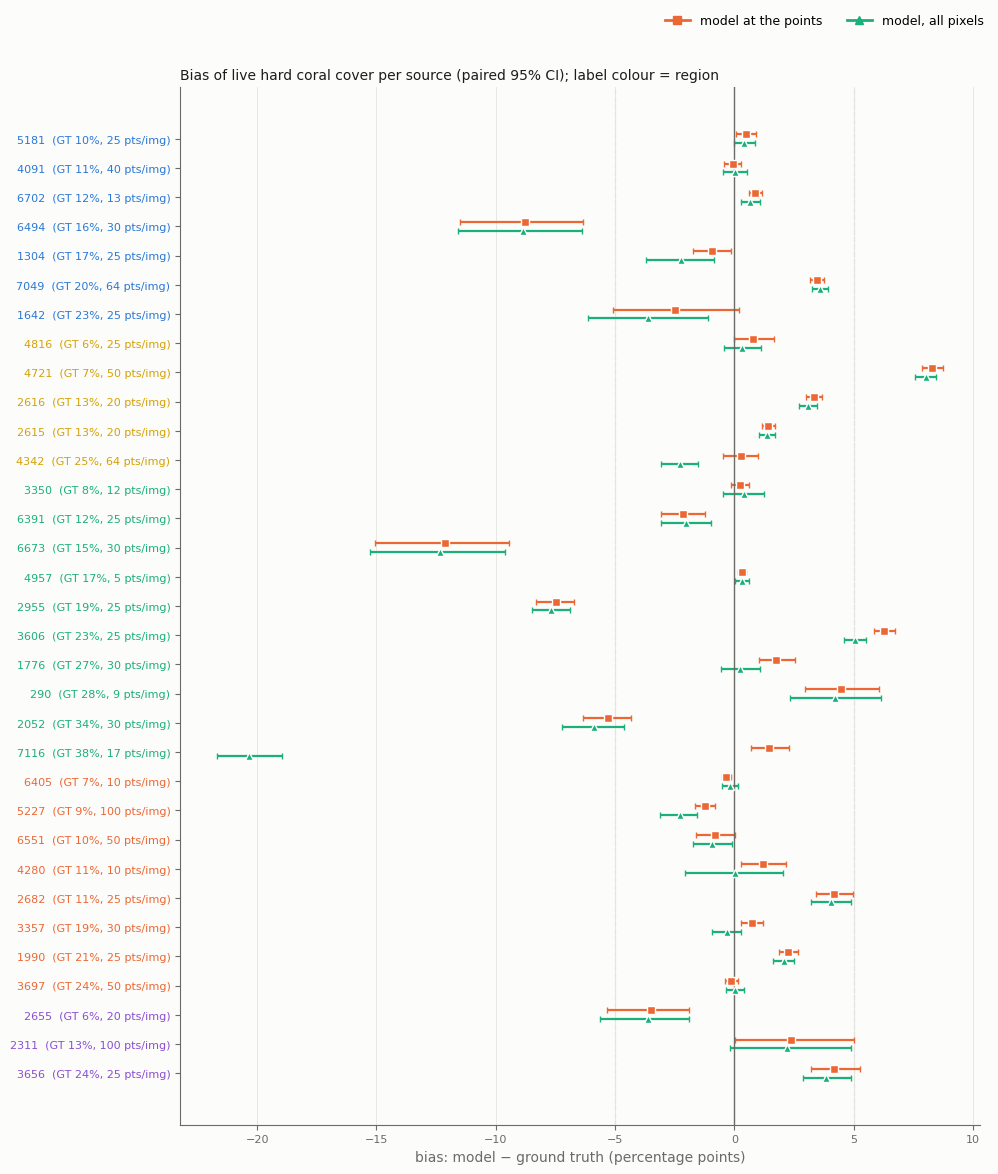

In [5]:
S_SRC = summarize("source")
src_label = lambda s: f"{s}  (GT {S_SRC.loc[s, 'truth']:.0%}, {S_SRC.loc[s, 'points/image']} pts/img)"
src_colors = [REGION_COLOR[REGION_OF[s]] for s in SOURCES]
t = show_summary(S_SRC)
t.insert(0, "region", [REGION_OF[s] for s in t.index])
display(t)
plot_bias(S_SRC, [src_label(s) for s in SOURCES], src_colors,
          "Bias of live hard coral cover per source (paired 95% CI); label colour = region")

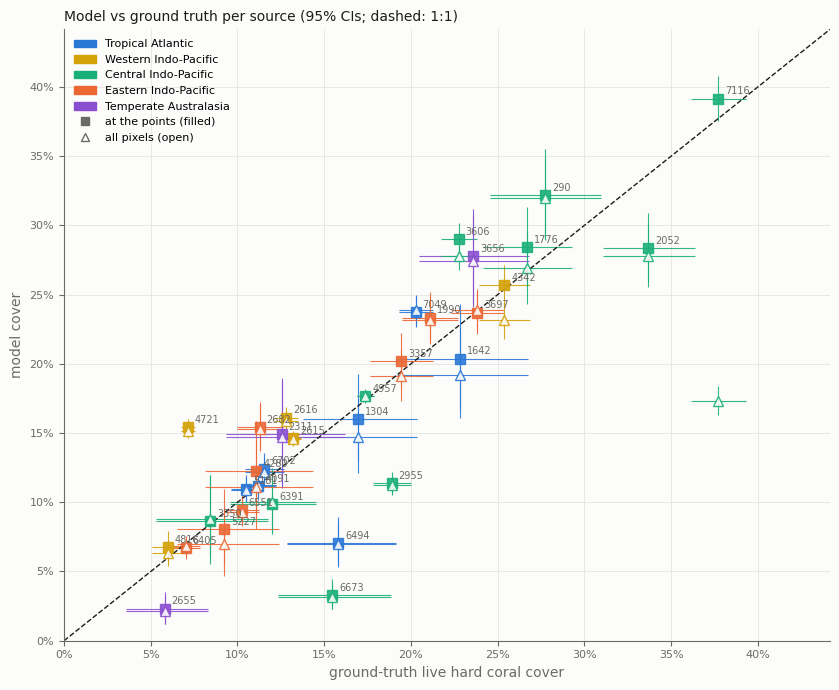

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 7))
for key, fill in (("model_points", True), ("model_dense", False)):
    _, _, marker = ESTIMATES[key]
    for s in SOURCES:
        r, c = S_SRC.loc[s], REGION_COLOR[REGION_OF[s]]
        ax.errorbar(r.truth, r[key], xerr=[[r.truth - r["truth lo"]], [r["truth hi"] - r.truth]],
                    yerr=[[r[key] - r[f"{key} lo"]], [r[f"{key} hi"] - r[key]]], fmt=marker, color=c, ms=7,
                    mfc=c if fill else SURFACE, mec=c, capsize=0, lw=0.8, alpha=0.9)
for s in SOURCES:
    ax.annotate(str(s), (S_SRC.loc[s, "truth"], S_SRC.loc[s, "model_points"]), xytext=(5, 3),
                textcoords="offset points", fontsize=7, color=MUTED)
lim = max(S_SRC.truth.max(), S_SRC[["model_points", "model_dense"]].max().max()) + 0.05
ax.plot([0, lim], [0, lim], color=INK, lw=1, ls="--")
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
ax.xaxis.set_major_formatter(pct)
ax.yaxis.set_major_formatter(pct)
ax.set_xlabel("ground-truth live hard coral cover")
ax.set_ylabel("model cover")
ax.set_title("Model vs ground truth per source (95% CIs; dashed: 1:1)")
handles = [Patch(color=c, label=r) for r, c in REGION_COLOR.items()]
handles += [Line2D([], [], color=MUTED, marker="s", lw=0, label="at the points (filled)"),
            Line2D([], [], color=MUTED, marker="^", mfc=SURFACE, lw=0, label="all pixels (open)")]
ax.legend(handles=handles, loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()

### 2.2 Where the bias comes from
At the points, model cover = ground-truth cover × recall / precision. Misses split into two kinds: coral whose
**order** is predicted as something else, and coral predicted scleractinia but **not live** (P(live) ≤ 0.5). The
false-positive labels are annotations that are not live hard coral but are predicted live hard coral; dead coral
among them (scleractinia with `live` negative) is a live-head error. Dead coral occurs in 6 of the sources.

In [7]:
err_rows = []
for s in SOURCES:
    d = pts[pts.source_id == s]
    fp = d[~d.live_gt & d.live_pred]
    miss = d[d.live_gt & ~d.live_pred]
    miss_order = miss[miss.pred_order != "scleractinia"]
    err_rows.append({
        "source": s, "region": REGION_OF[s], "GT cover (points)": d.live_gt.mean(), "model cover (points)": d.live_pred.mean(),
        "recall / precision": S_SRC.loc[s, "recall"] / S_SRC.loc[s, "precision"],
        "false positives": len(fp), "of which dead coral": int(((fp.gt_code == 2) & (fp.gt_live_code == 1)).sum()),
        "dead coral points": int(((d.gt_code == 2) & (d.gt_live_code == 1)).sum()),
        "misses": len(miss), "misses: other order": len(miss_order), "misses: scler. but not live": len(miss) - len(miss_order),
        "top false-positive labels": ", ".join(f"{l} ({n})" for l, n in fp.label.value_counts().head(3).items()),
        "top misses: label → predicted order": ", ".join(
            f"{l} → {o} ({n})" for (l, o), n in miss.groupby(["label", "pred_order"]).size()
            .sort_values(ascending=False).head(3).items()),
    })
errs = pd.DataFrame(err_rows).set_index("source")
errs.style.format({"GT cover (points)": "{:.1%}", "model cover (points)": "{:.1%}", "recall / precision": "{:.2f}"})

,region,GT cover (points),model cover (points),recall / precision,false positives,of which dead coral,dead coral points,misses,misses: other order,misses: scler. but not live,top false-positive labels,top misses: label → predicted order
source,,,,,,,,,,,,
5181,Tropical Atlantic,10.4%,10.9%,1.05,621,0,0,490,452,38,"turf algae (122), shadow (99), sponge other (71)","montastraea cavernosa - bleached → zoantharia (62), montastraea cavernosa → zoantharia (47), bleached porites astreoides → none (27)"
4091,Tropical Atlantic,11.2%,11.1%,0.99,313,0,0,324,313,11,"thick turf algae (70), sponge other (69), gorgoniidae (41)","agaricia agaricites → none (103), siderastrea siderea → none (40), porites astreoides → none (32)"
6702,Tropical Atlantic,11.5%,12.4%,1.08,268,0,0,110,105,5,"coral:rock (114), unknown coral (55), unidentified (27)","montastraea cavernosa → none (34), porites astreoides → none (21), colpophyllia natans → none (10)"
6494,Tropical Atlantic,15.8%,7.0%,0.45,42,0,62,392,384,8,"transect hardware (13), dictyota spp (6), gorgonia ventalina (4)","orbicella → none (106), agaricia agaricites → none (52), orbicella annularis → none (36)"
1304,Tropical Atlantic,17.0%,16.0%,0.94,43,0,0,69,65,4,"rock_pavement (16), sponge (7), macroalgae (6)","other hard coral → none (32), acropora cervicornis → none (18), acropora cervicornis → malacalcyonacea (7)"
7049,Tropical Atlantic,20.3%,23.8%,1.17,3046,1749,24382,442,385,57,"acropora cervicornis dead (1749), live coral (408), sand (395)","acropora cervicornis → none (334), acropora cervicornis → scleractinia (57), acropora cervicornis → malacalcyonacea (39)"
1642,Tropical Atlantic,22.8%,20.4%,0.89,245,0,0,335,252,83,"millepora (86), dead coral (45), zoanthid (33)","other hard coral → none (92), porites furcata → none (69), porites furcata → scleractinia (43)"
4816,Western Indo-Pacific,6.1%,6.8%,1.13,435,0,0,307,293,14,"turf algae (156), cca (crustose coralline algae) (100), sponge (62)","hard coral → none (258), hard coral (massive) → none (24), hard coral → scleractinia (14)"
4721,Western Indo-Pacific,7.1%,15.4%,2.16,13781,128,2689,1623,1244,379,"condition_fully bleached (3909), condition_full bleach & partial mortality (1726), condition_paling (1377)","cred-porites spp_massive → none (390), cred-porites spp_massive → scleractinia (76), pocillopora → scleractinia (74)"


### 2.3 How estimates converge with the number of images
For each source and n, the same 2,000 random n-image surveys are scored with all three estimates. Lines show the
error that 95% of surveys stay within, measured against the source's ground-truth cover. The ground truth's own line
falls as 1/√n; a model line flattens out at its bias.

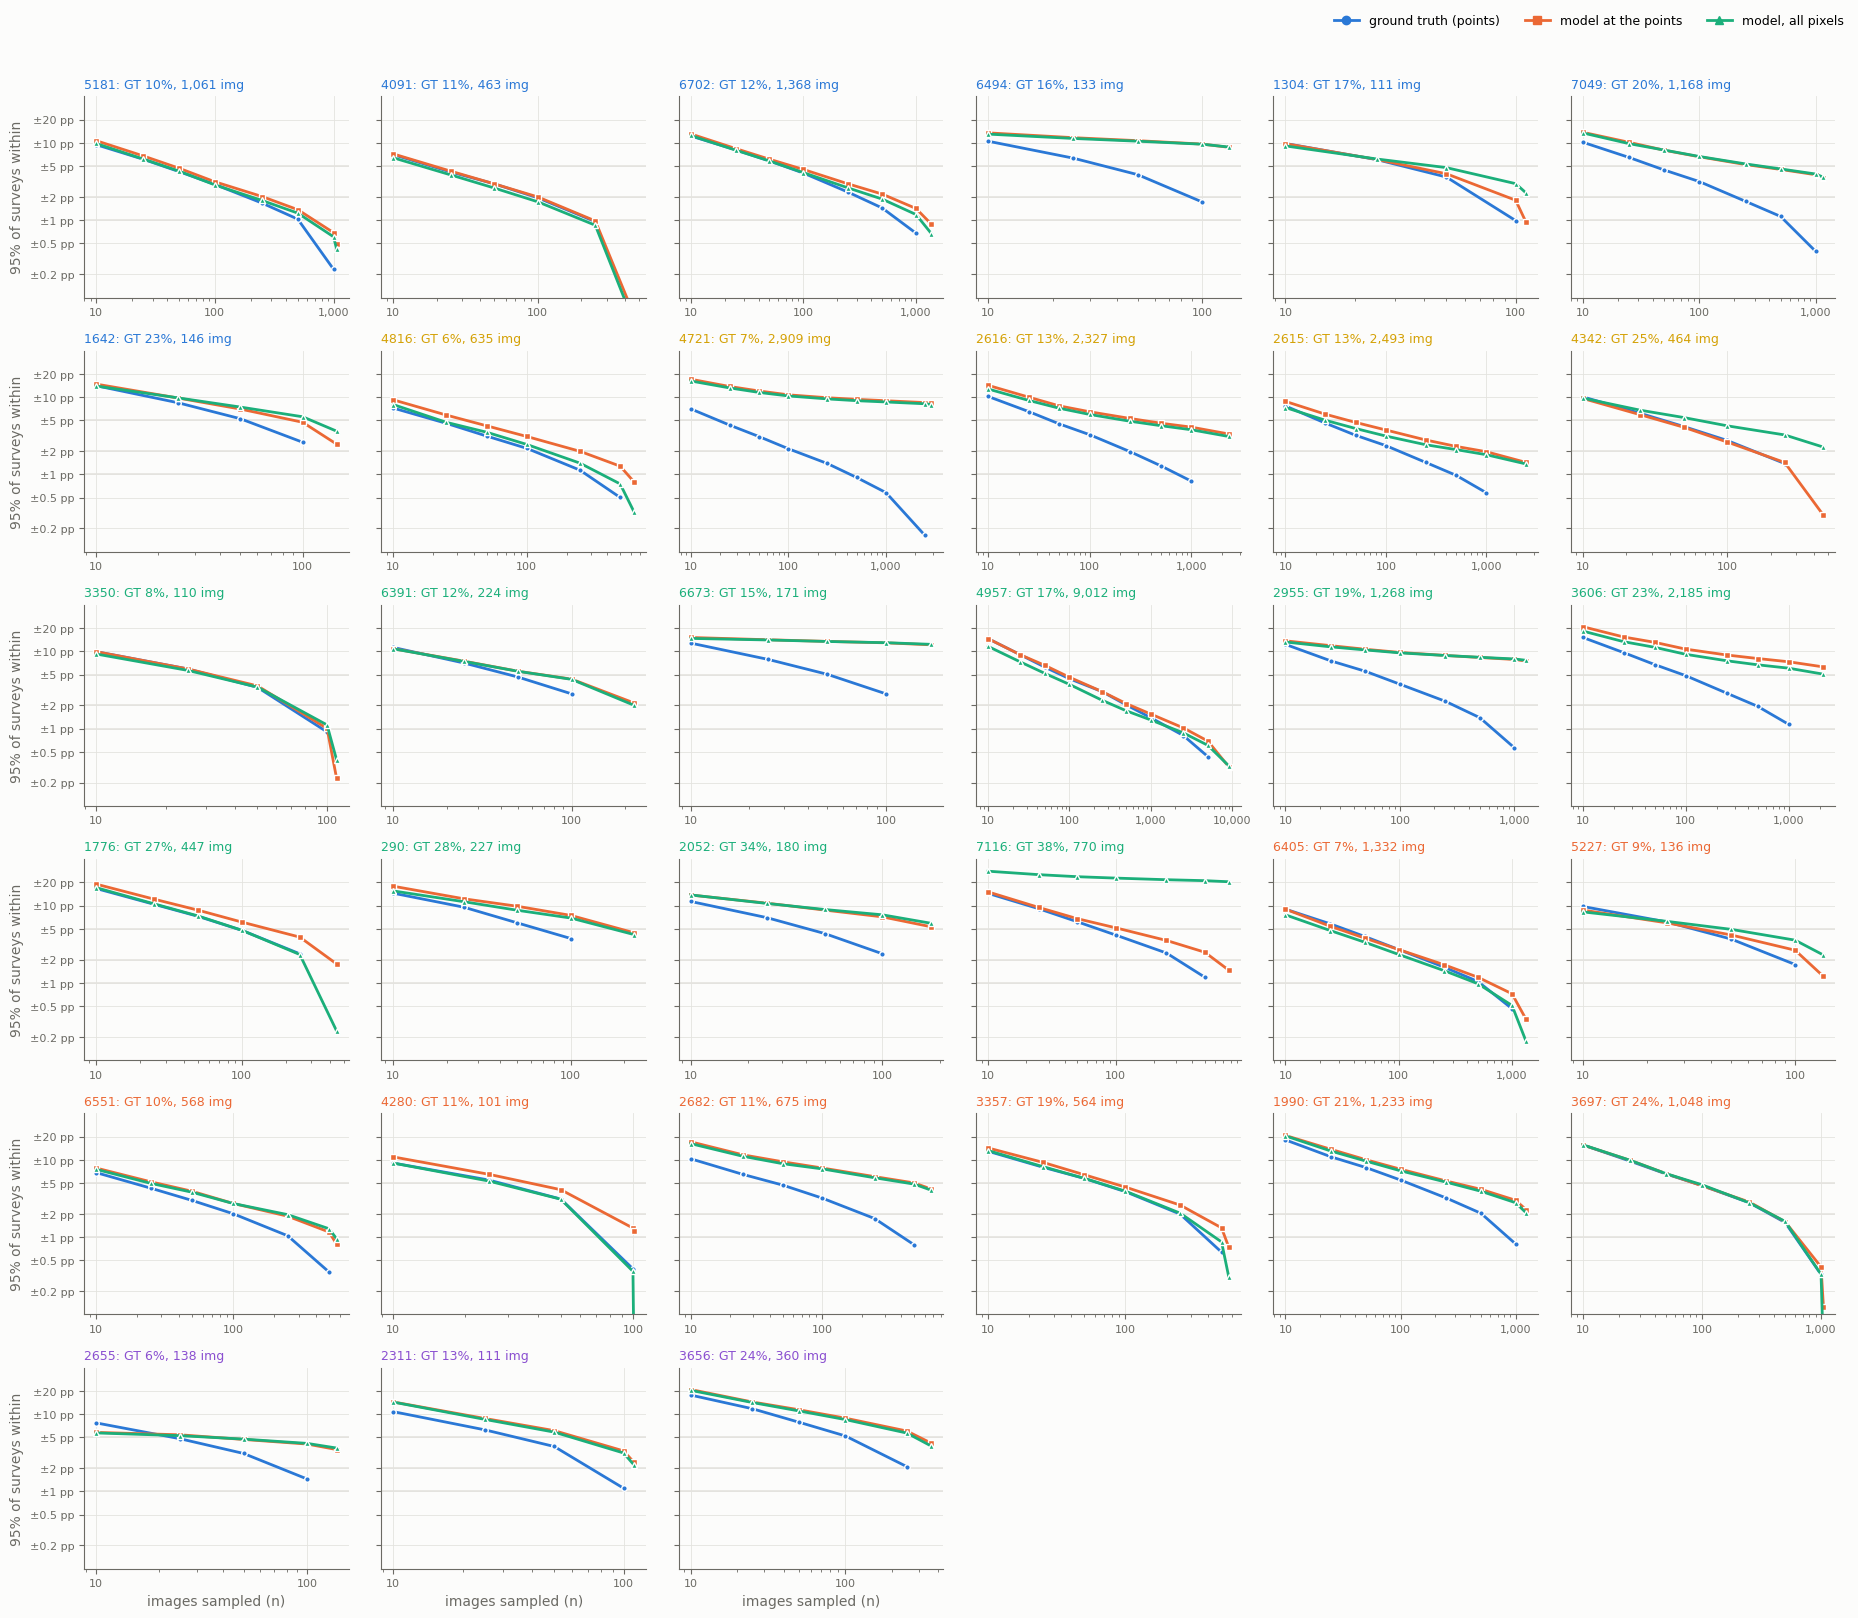

In [8]:
CONV_SRC = convergence("source")
plot_convergence(CONV_SRC, "source", ncols=6, panel_w=3.1, panel_h=2.6)

In [9]:
NEED_SRC = images_needed("source")
show_need(NEED_SRC)

## 3. Per biogeographic region
Each region pools the images of its sources; a survey of n images draws them at random from that pool. The region's
ground truth is the mean over all of its images, so large sources weigh more (see the composition table in section 1).

,sources,images,points/image,ground truth,model at the points,"bias, points (pp)","model, all pixels","bias, all pixels (pp)",precision,recall,r per image (points),r per image (pixels)
group,,,,,,,,,,,,
Tropical Atlantic,7,4450,25,"14.2% [13.7%, 14.7%]",15.1%,"+0.9 [+0.7, +1.1]",15.0%,"+0.8 [+0.6, +1.1]",0.83,0.91,0.93,0.90
Western Indo-Pacific,5,8828,20,"11.2% [10.9%, 11.5%]",15.3%,"+4.1 [+3.9, +4.3]",15.0%,"+3.8 [+3.5, +4.0]",0.58,0.85,0.79,0.73
Central Indo-Pacific,10,14594,5,"19.9% [19.5%, 20.2%]",20.3%,"+0.5 [+0.3, +0.6]",18.9%,"-0.9 [-1.2, -0.7]",0.82,0.83,0.91,0.78
Eastern Indo-Pacific,8,5657,25,"15.4% [14.8%, 16.0%]",16.3%,"+0.9 [+0.7, +1.1]",16.1%,"+0.7 [+0.5, +0.9]",0.87,0.91,0.96,0.94
Temperate Australasia,3,609,25,"17.5% [15.4%, 19.7%]",19.7%,"+2.1 [+1.3, +3.0]",19.4%,"+1.9 [+1.0, +2.8]",0.76,0.87,0.92,0.92


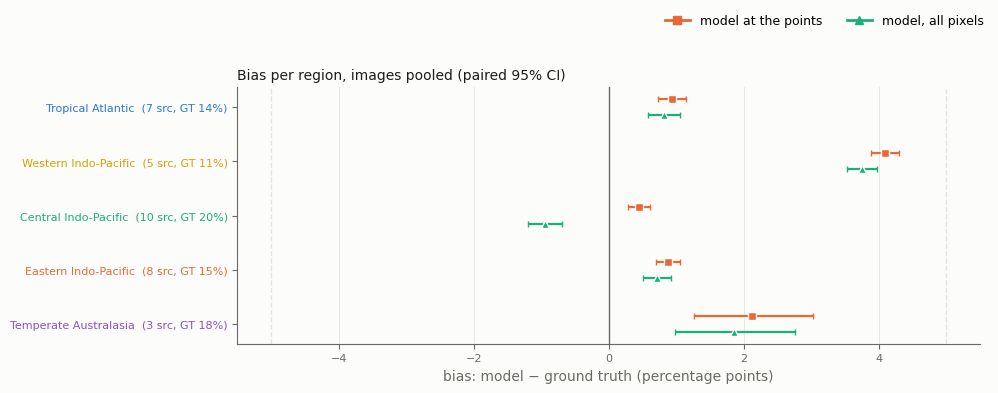

In [10]:
S_REG = summarize("region")
display(show_summary(S_REG))
plot_bias(S_REG, [f"{r}  ({S_REG.loc[r, 'sources']} src, GT {S_REG.loc[r, 'truth']:.0%})" for r in REGIONS],
          [REGION_COLOR[r] for r in REGIONS], "Bias per region, images pooled (paired 95% CI)", height_per_row=0.55)

Per image within each region (one dot per image; orange at the points, green all pixels).

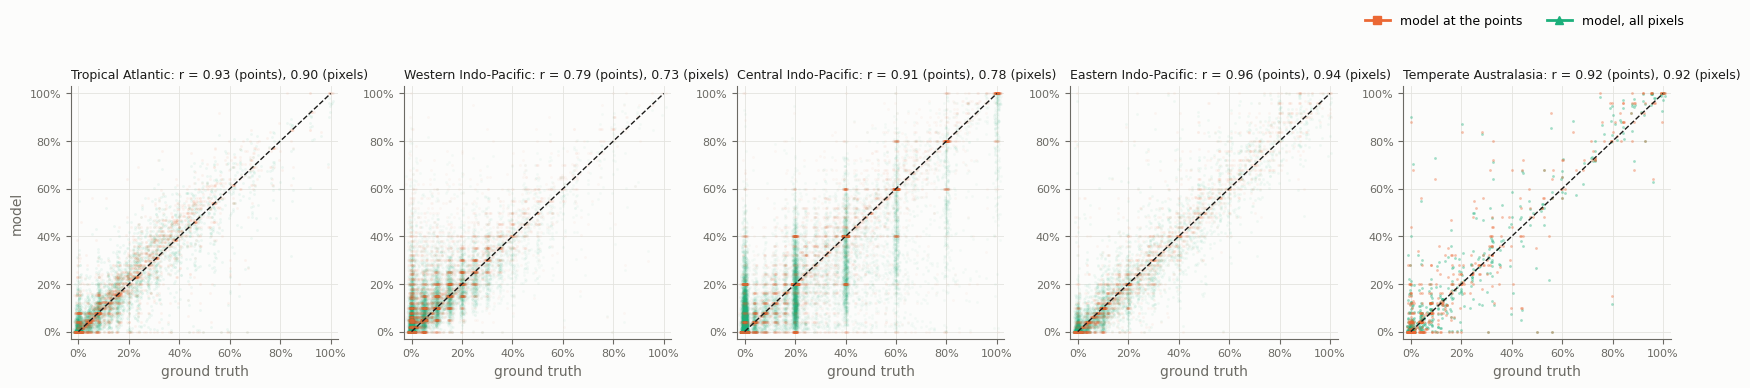

In [11]:
plot_scatter("region", ncols=5)

### 3.1 Spread of the source biases within a region
The pooled bias of a region can hide sources that are biased in opposite directions. Below, each source's bias
(dot size ∝ images) and the region's pooled bias (bar with 95% CI).

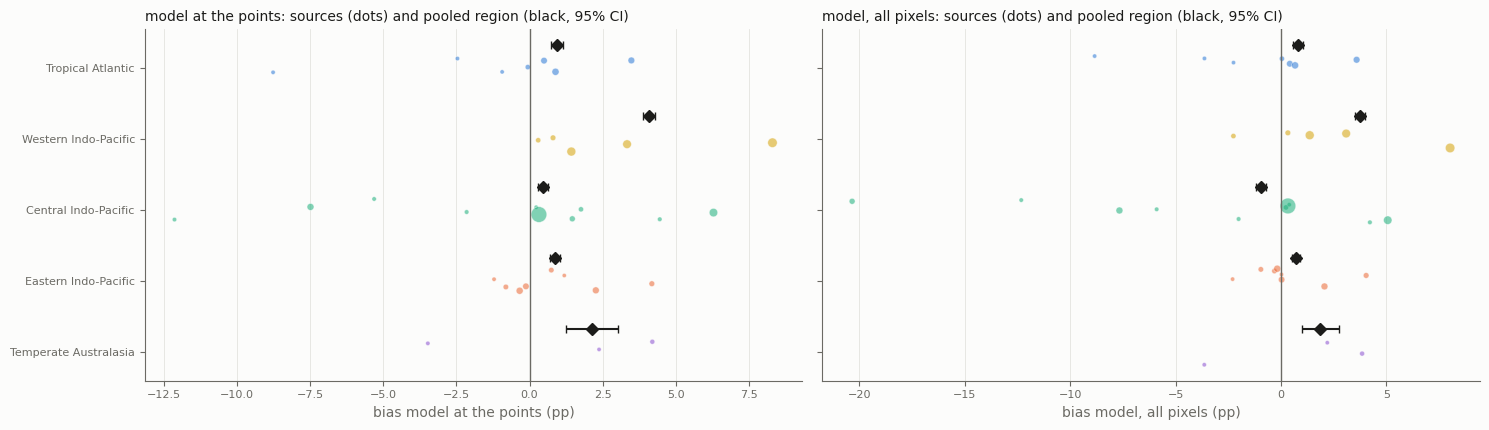

,points: pooled bias,points: mean |source bias|,points: min source bias,points: max source bias,pixels: pooled bias,pixels: mean |source bias|,pixels: min source bias,pixels: max source bias
Tropical Atlantic,0.9,2.4,-8.8,3.5,0.8,2.8,-8.8,3.6
Western Indo-Pacific,4.1,2.8,0.3,8.3,3.8,3.0,-2.3,8.0
Central Indo-Pacific,0.5,4.2,-12.1,6.3,-0.9,5.8,-20.3,5.1
Eastern Indo-Pacific,0.9,1.4,-1.2,4.2,0.7,1.2,-2.3,4.0
Temperate Australasia,2.1,3.4,-3.5,4.2,1.9,3.2,-3.6,3.9


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4), sharey=True)
y = {r: i for i, r in enumerate(REGIONS)}
for ax, key in zip(axes, ("model_points", "model_dense")):
    for r, ss in REGIONS.items():
        b = 100 * S_SRC.loc[ss, f"bias {key}"]
        ax.scatter(b, np.full(len(ss), y[r]) + rng.uniform(-0.18, 0.18, len(ss)), s=8 + 120 * S_SRC.loc[ss, "images"] / S_SRC.images.max(),
                   color=REGION_COLOR[r], alpha=0.55, edgecolor="white", lw=0.5, zorder=2)
        rr = S_REG.loc[r]
        ax.errorbar(100 * rr[f"bias {key}"], y[r] - 0.32, xerr=[[100 * (rr[f"bias {key}"] - rr[f"bias {key} lo"])],
                                                               [100 * (rr[f"bias {key} hi"] - rr[f"bias {key}"])]],
                    fmt="D", color=INK, ms=6, capsize=3, lw=1.5, zorder=3)
    ax.axvline(0, color=MUTED, lw=1)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(f"bias {ESTIMATES[key][0]} (pp)")
    ax.set_title(f"{ESTIMATES[key][0]}: sources (dots) and pooled region (black, 95% CI)")
axes[0].set_yticks(list(y.values()), list(y))
axes[0].invert_yaxis()
fig.tight_layout()
plt.show()

spread = pd.DataFrame({
    r: {f"{kind}: {stat}": f(100 * S_SRC.loc[ss, f"bias {key}"])
        for kind, key in (("points", "model_points"), ("pixels", "model_dense"))
        for stat, f in (("pooled bias", lambda _, r=r, key=key: 100 * S_REG.loc[r, f"bias {key}"]),
                        ("mean |source bias|", lambda b: b.abs().mean()),
                        ("min source bias", lambda b: b.min()), ("max source bias", lambda b: b.max()))}
    for r, ss in REGIONS.items()}).T
spread.round(1)

### 3.2 How region-level estimates converge

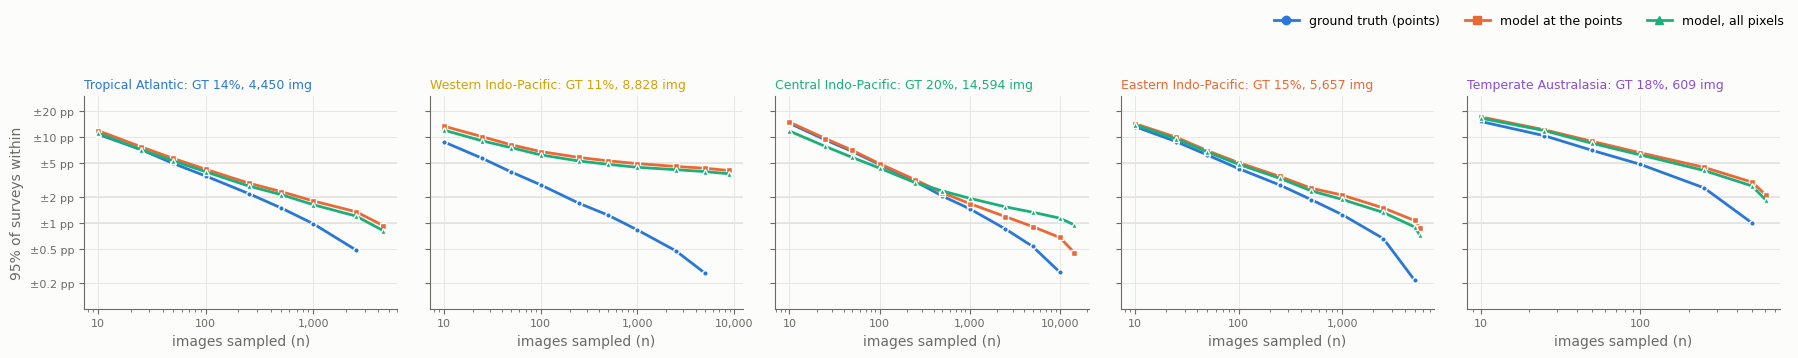

In [13]:
CONV_REG = convergence("region")
plot_convergence(CONV_REG, "region", ncols=5, ylim=(0.1, 30))
NEED_REG = images_needed("region")
show_need(NEED_REG)

Other summaries of the same 2,000 surveys per n. **Mean |error|** is the typical miss of an n-image survey.
**RMSE** = √(bias² + variance of the survey mean): a model line flattens at |bias| as n grows, like the 95% line but
lower. For the ground truth, RMSE is the standard error of an n-image survey (0 at all images, as sampling is without
replacement).

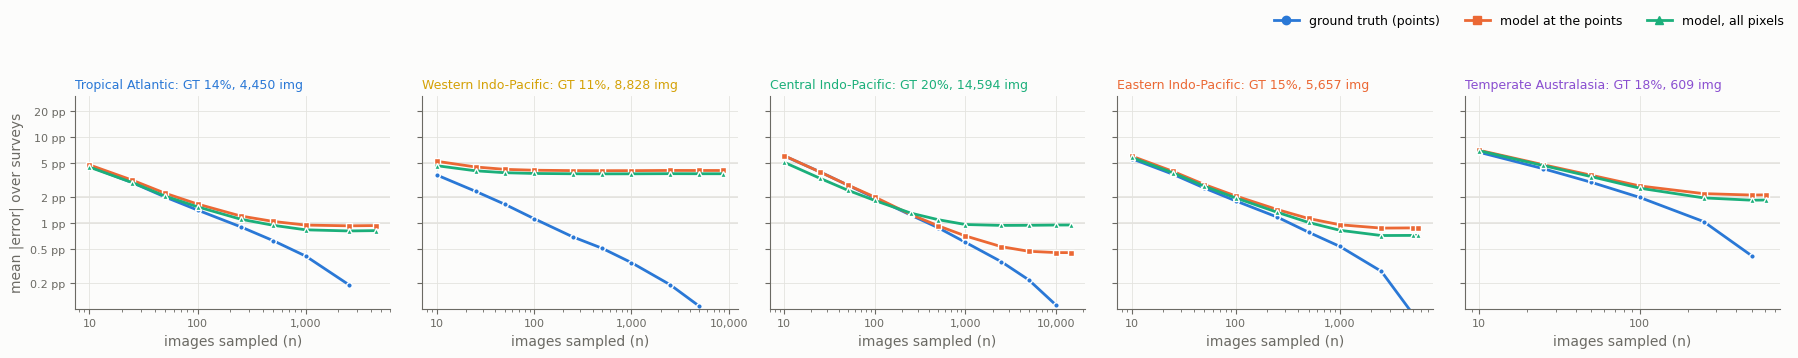

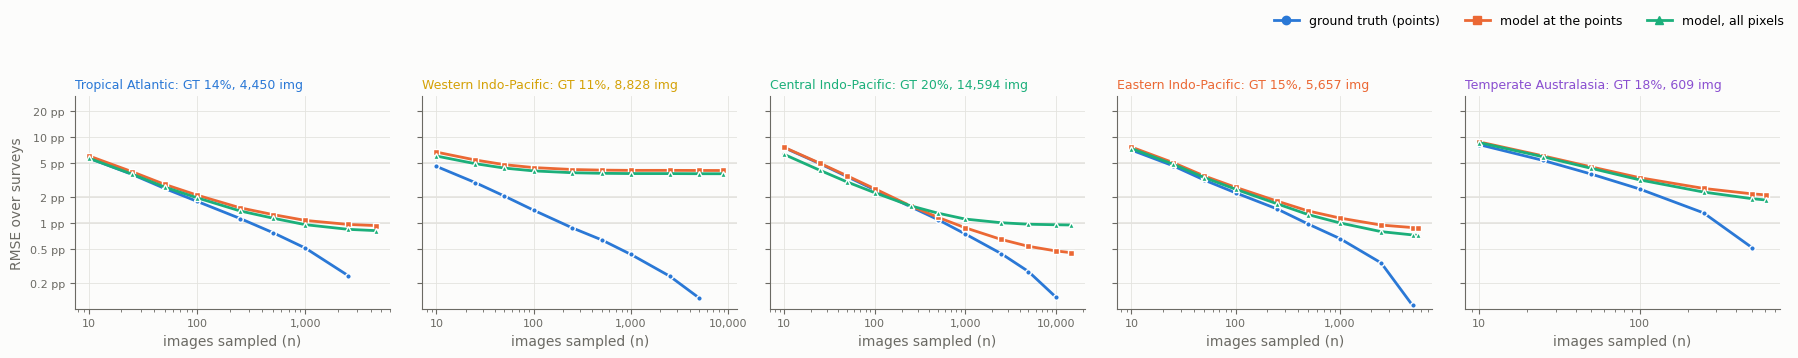

In [14]:
for stat in ("mean |error|", "RMSE"):
    plot_convergence(CONV_REG, "region", ncols=5, ylim=(0.1, 30), stat=stat)

#### Sources weighted equally
Above, a survey draws images from the region's pool, so large sources dominate both the survey and the target. Here
every source counts the same, as in a stratified survey: the n images are spread evenly over the region's sources
(drawn without replacement within each source; a source that runs out keeps all its images and the rest go to the
others), and the estimate is the **mean of the per-source means**. The target is the mean of the sources' ground-truth
covers (the GT in the panel titles), and the model's bias is measured against it, so it can differ from the pooled
bias. The grid starts at n = number of sources, and the ground truth's error is 0 at n = all images.

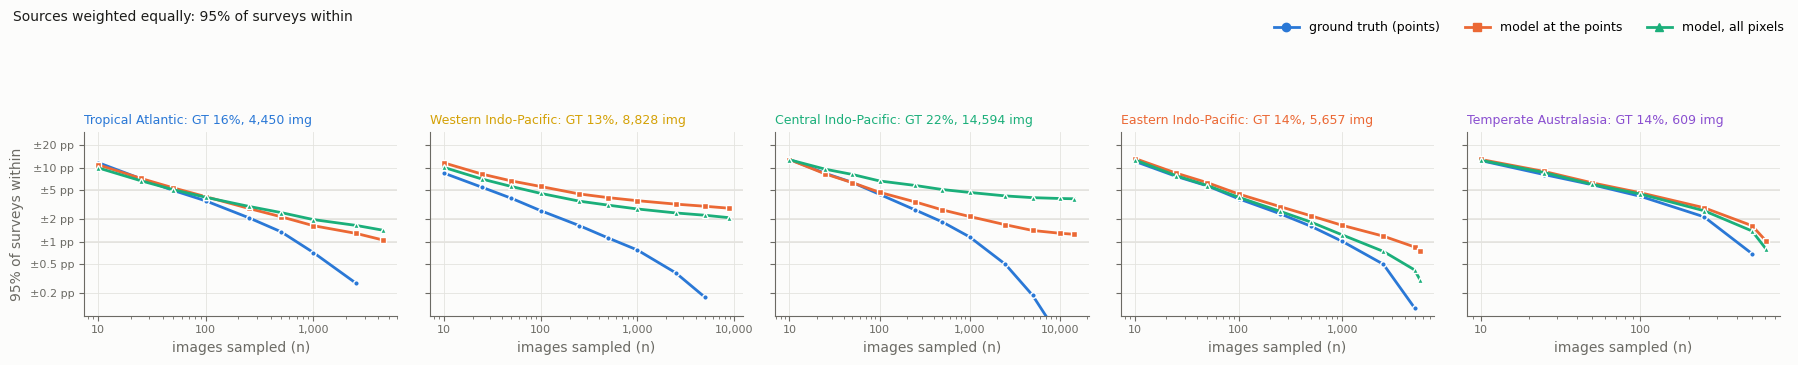

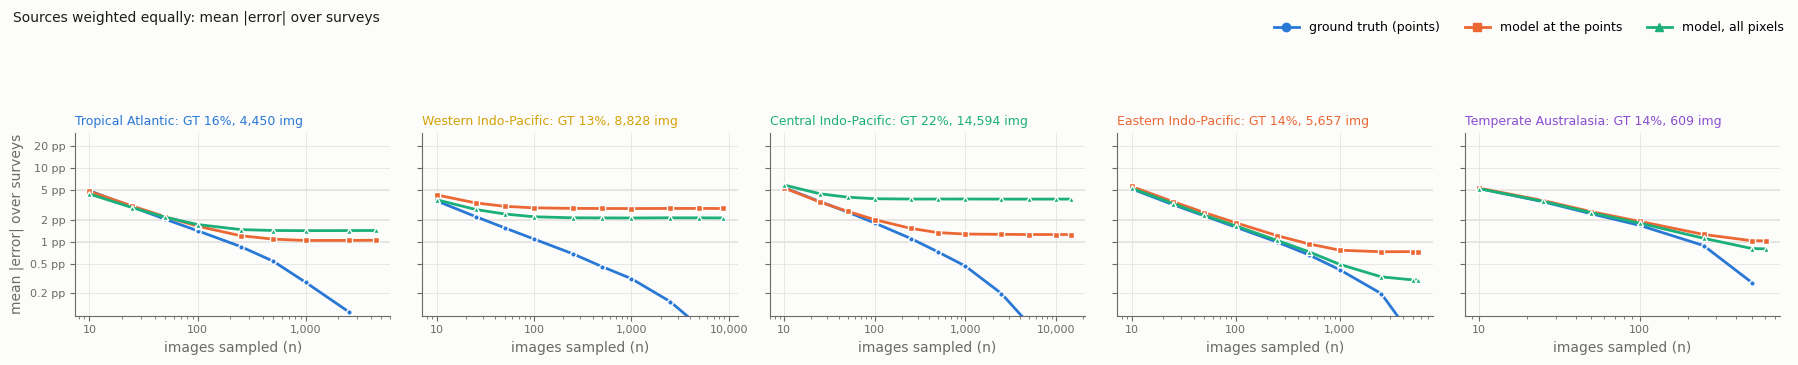

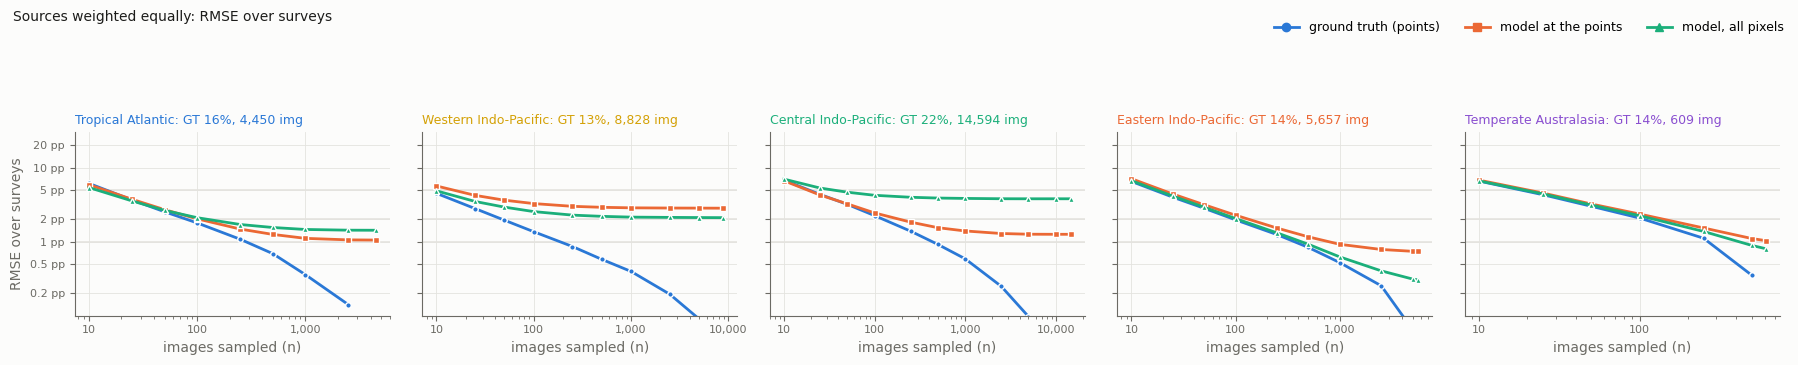

,"GT, pooled images","GT, sources equal","bias, all pixels (pooled)","bias, all pixels (sources equal)"
Tropical Atlantic,14.2%,15.6%,0.8%,-1.4%
Western Indo-Pacific,11.2%,12.9%,3.8%,2.1%
Central Indo-Pacific,19.9%,22.1%,-0.9%,-3.8%
Eastern Indo-Pacific,15.4%,14.2%,0.7%,0.3%
Temperate Australasia,17.5%,14.0%,1.9%,0.8%


In [15]:
CONV_REG_SRC = convergence("region", by_source=True)
for stat in ERROR_STATS:
    plot_convergence(CONV_REG_SRC, "region", ncols=5, ylim=(0.1, 30), stat=stat,
                     title=f"Sources weighted equally: {ERROR_STATS[stat][0]}")
src_mean = lambda g, i: np.mean([X["region"][g][i][images.loc[images.region == g, "source_id"].to_numpy() == s].mean()
                                 for s in REGIONS[g]])
tgt = pd.DataFrame({
    "GT, pooled images": [X["region"][g][0].mean() for g in REGIONS],
    "GT, sources equal": [src_mean(g, 0) for g in REGIONS],
    "bias, all pixels (pooled)": [X["region"][g][2].mean() - X["region"][g][0].mean() for g in REGIONS],
    "bias, all pixels (sources equal)": [src_mean(g, 2) - src_mean(g, 0) for g in REGIONS],
}, index=list(REGIONS))
tgt.style.format("{:.1%}").set_caption("Ground-truth live hard coral cover (target) and model bias per region")

Both designs on one plot: images pooled (solid; target = mean over the region's images) and sources weighted equally
(dashed; target = mean of the source covers). Rows are the three error summaries; titles give both targets.

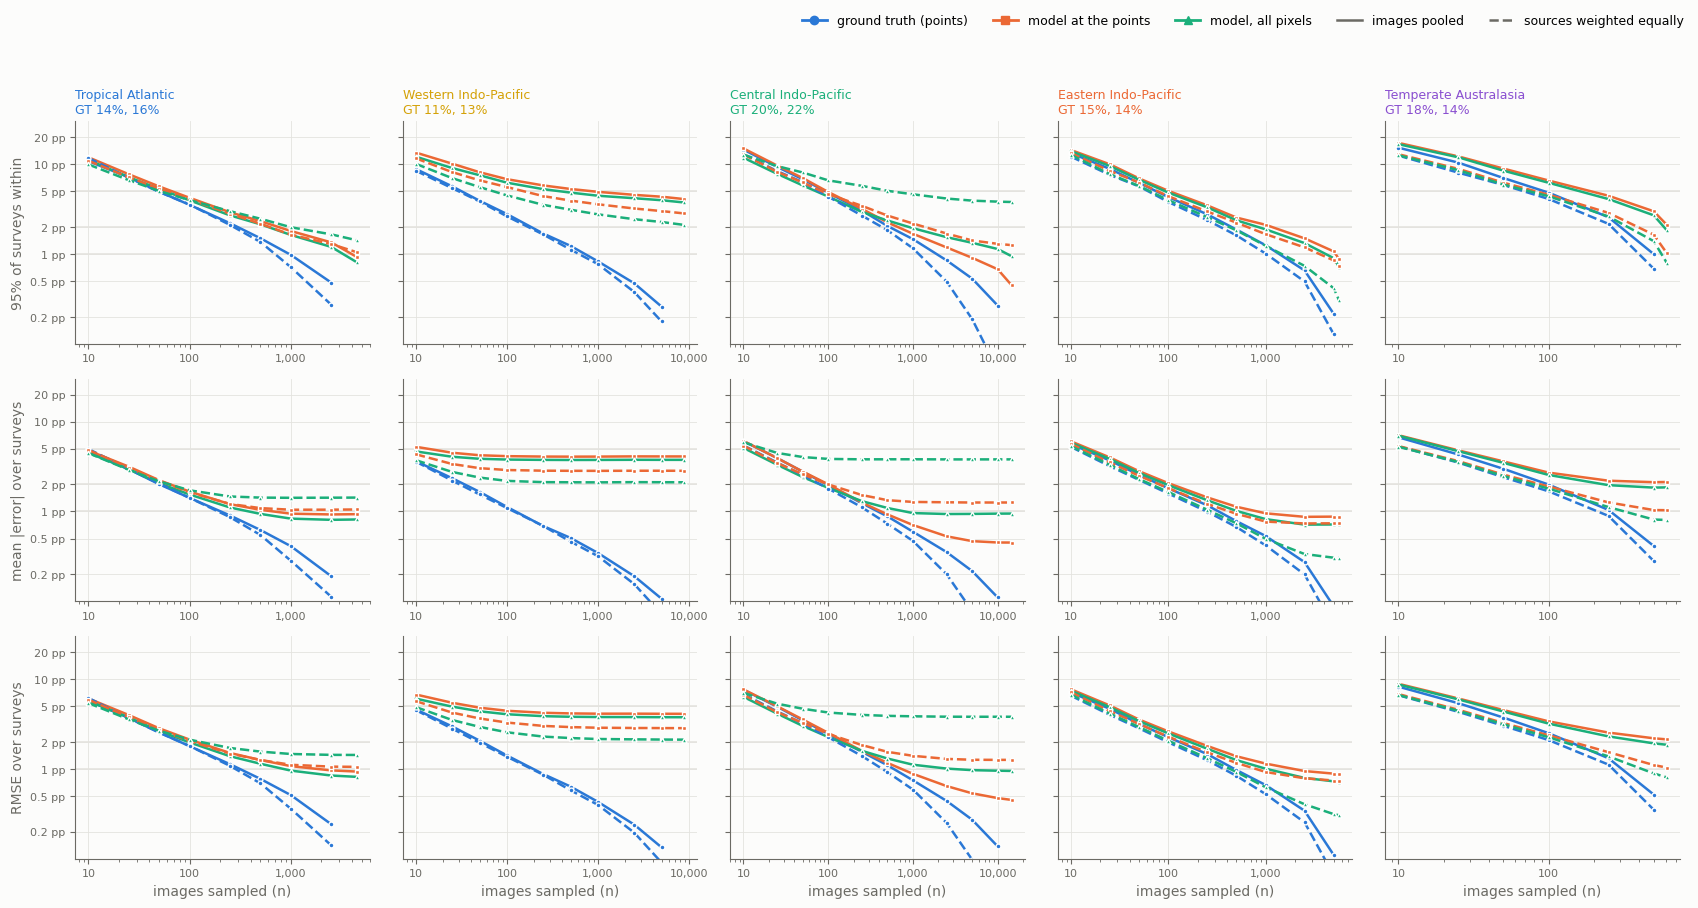

In [16]:
plot_convergence_compare({"images pooled": (CONV_REG, "-"), "sources weighted equally": (CONV_REG_SRC, "--")},
                         "region")

## 4. All test data
All 33 sources pooled; a survey of n images draws them at random from all test images.

The error figure has one row per error summary (as in section 3): the error that 95% of surveys stay within,
the mean |error|, and the RMSE, for every region and for all test data.


,sources,images,points/image,ground truth,model at the points,"bias, points (pp)","model, all pixels","bias, all pixels (pp)",precision,recall,r per image (points),r per image (pixels)
group,,,,,,,,,,,,
all test,33,34138,20,"16.1% [15.9%, 16.3%]",17.7%,"+1.6 [+1.5, +1.7]",16.9%,"+0.8 [+0.7, +1.0]",0.76,0.87,0.91,0.82


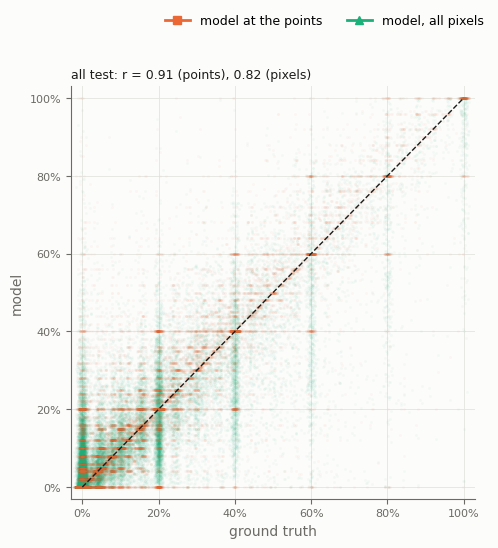

In [17]:
S_ALL = summarize("all")
display(show_summary(S_ALL))
plot_scatter("all", ncols=1, panel=5)

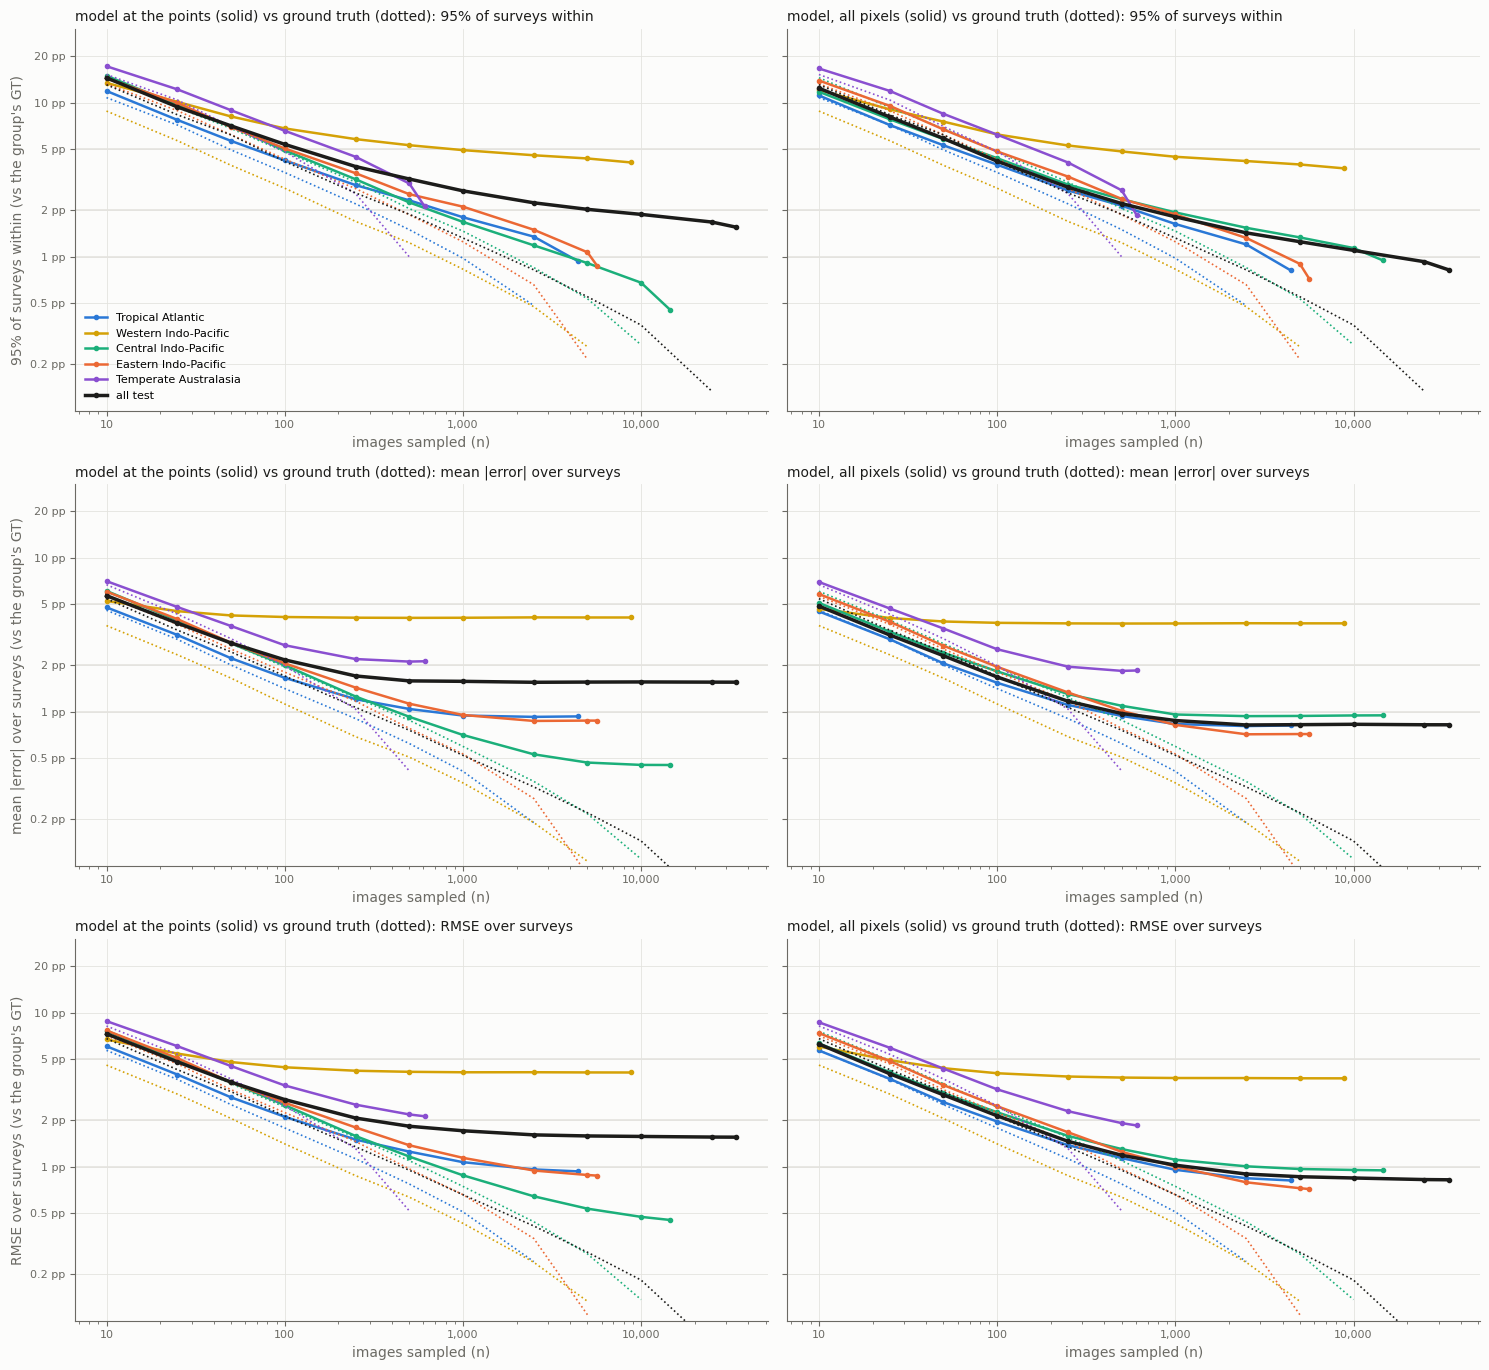

In [18]:
CONV_ALL = convergence("all")
NEED_ALL = images_needed("all")
display(show_need(NEED_ALL))

# Error curves of all regions and of all test data on one plot, one row per error summary (as in section 3):
# model (solid; left at the points, right all pixels) and ground truth (dotted), against each group's GT cover.
# Mean |error| and RMSE flatten at |bias| for the model as n grows; for the ground truth they reach 0 at all images.
fig, axes = plt.subplots(len(ERROR_STATS), 2, figsize=(15, 4.6 * len(ERROR_STATS)), sharey=True, squeeze=False)
for row, (stat, (ylabel, _)) in zip(axes, ERROR_STATS.items()):
    pm = "±" if stat == "error vs GT (95%)" else ""
    for ax, key in zip(row, ("model_points", "model_dense")):
        for conv, lvl in ((CONV_REG, "region"), (CONV_ALL, "all")):
            for g in X[lvl]:
                color = REGION_COLOR.get(g, INK)
                n_all = X[lvl][g].shape[1]
                c = conv[(conv.group == g) & (conv.estimate == key)]
                ax.plot(c.n, 100 * c[stat], color=color, lw=2.5 if lvl == "all" else 1.8, marker="o", ms=3, label=g)
                c = conv[(conv.group == g) & (conv.estimate == "truth") & (conv.n < n_all)]
                ax.plot(c.n, 100 * c[stat], color=color, lw=1.2, ls=":")
        for lv in (5, 2, 1):
            ax.axhline(lv, color=GRID, lw=1.2, zorder=0)
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_ylim(0.1, 30)
        ax.yaxis.set_major_locator(mticker.FixedLocator([0.2, 0.5, 1, 2, 5, 10, 20]))
        ax.yaxis.set_minor_locator(mticker.NullLocator())
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _, pm=pm: f"{pm}{v:g} pp"))
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{int(v):,}"))
        ax.set_xlabel("images sampled (n)")
        ax.set_title(f"{ESTIMATES[key][0]} (solid) vs ground truth (dotted): {ylabel}")
    row[0].set_ylabel(f"{ylabel} (vs the group's GT)")
axes[0, 0].legend(fontsize=8, loc="lower left")
fig.tight_layout()
plt.show()

# The same summaries as numbers for all test data, at selected n.
conv_tab = CONV_ALL[CONV_ALL.n.isin([10, 25, 50, 100, 250, 500, 1000, 2500])].copy()
conv_tab["estimate"] = conv_tab.estimate.map(lambda k: ESTIMATES[k][0])
display(conv_tab.pivot_table(index="n", columns="estimate", values=list(ERROR_STATS), sort=False)
        .mul(100).round(2).style.format("{:.2f}").set_caption("All test data: survey error in pp, per n"))


### Relative error: how far a survey under- or overestimates
Signed error of an n-image survey as a share of the group's ground-truth cover: (estimate − GT) / GT. For example, a
true cover of 50% estimated as 51% is +2%. Lines: mean over the surveys (the relative bias once n is large). Band:
the range that 95% of surveys fall in (2.5th–97.5th percentile). Above 0 is an overestimate, below 0 an
underestimate. Uses its own random generator, so the cells below are unchanged.


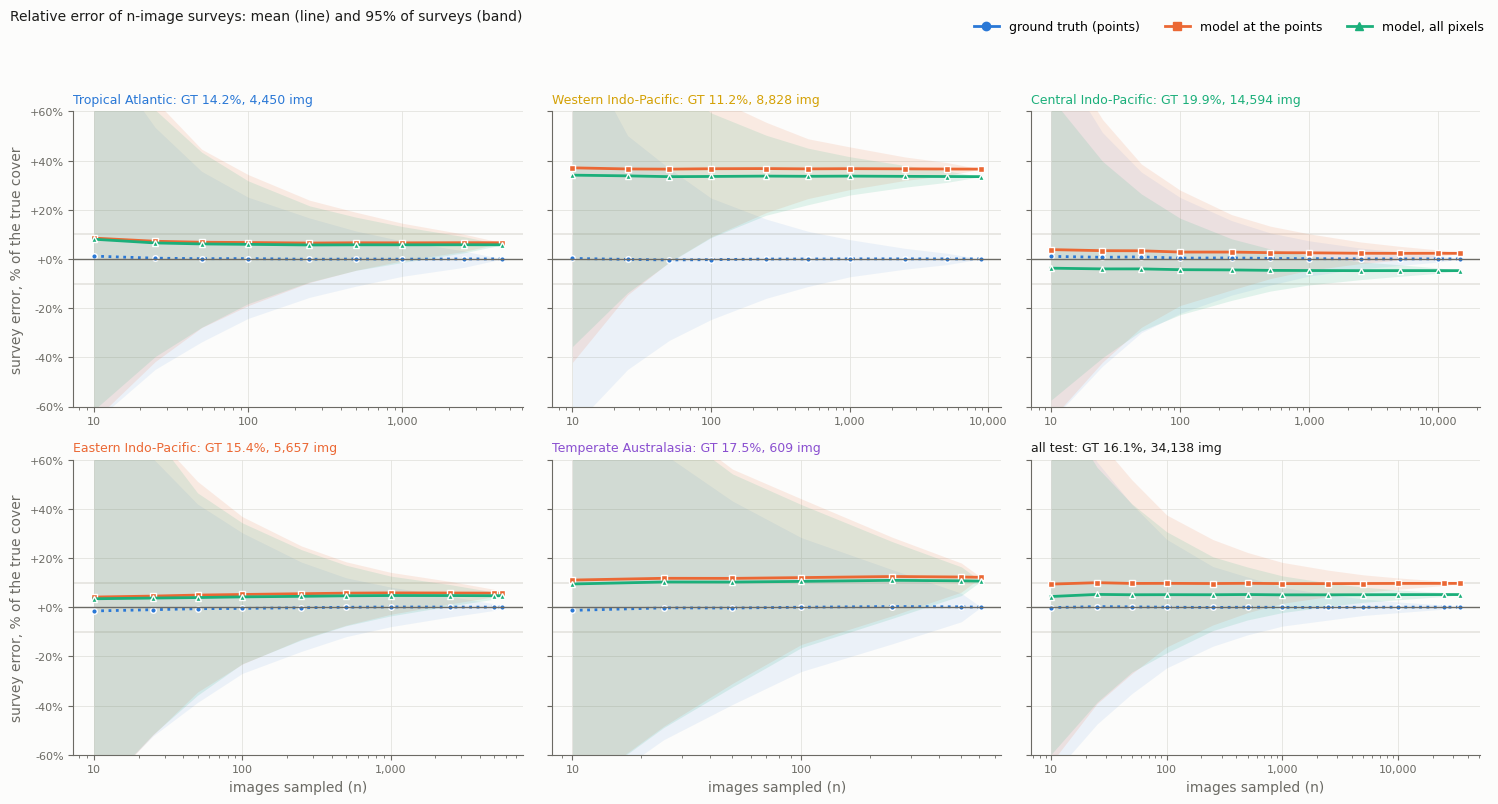

In [19]:
gen_rel = np.random.default_rng(SEED + 2)
rel_rows = []
groups_rel = [("region", g) for g in X["region"]] + [("all", g) for g in X["all"]]
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
for ax, (lvl, g) in zip(axes.flat, groups_rel):
    x = X[lvl][g]
    n_all = x.shape[1]
    ns = np.array([m for m in N_GRID if m < n_all] + [n_all])
    target = x[0].mean()
    rel = 100 * survey_errors(x, ns, R, gen=gen_rel) / target  # (3, R, len(ns)), % of the true cover
    for i, (key, (label, color, marker)) in enumerate(ESTIMATES.items()):
        mean, lo, hi = rel[i].mean(axis=0), *np.quantile(rel[i], [0.025, 0.975], axis=0)
        ax.fill_between(ns, lo, hi, color=color, alpha=0.12 if key != "truth" else 0.08, lw=0)
        ax.plot(ns, mean, color=color, marker=marker, ms=4, mec="white", lw=2, ls="-" if key != "truth" else ":")
        rel_rows += [{"group": g, "n": n, "estimate": label, "mean": m, "2.5%": l, "97.5%": h}
                     for n, m, l, h in zip(ns, mean, lo, hi)]
    ax.axhline(0, color=MUTED, lw=1)
    for lv in (-10, 10):
        ax.axhline(lv, color=GRID, lw=1.2, zorder=0)
    ax.set_xscale("log")
    ax.set_ylim(-60, 60)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:+.0f}%"))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{int(v):,}"))
    ax.set_title(f"{g}: GT {target:.1%}, {n_all:,} img", fontsize=9, color=REGION_COLOR.get(g, INK))
for ax in axes[-1]:
    ax.set_xlabel("images sampled (n)")
for ax in axes[:, 0]:
    ax.set_ylabel("survey error, % of the true cover")
legend(fig, ncol=3)
fig.suptitle("Relative error of n-image surveys: mean (line) and 95% of surveys (band)", x=0.01, y=1.0, ha="left",
             va="top", fontsize=10, color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

REL = pd.DataFrame(rel_rows)
rel_all = REL[(REL.group == "all test") & REL.n.isin([10, 25, 50, 100, 250, 500, 1000, 2500, X["all"]["all test"].shape[1]])]
display(rel_all.pivot_table(index="n", columns="estimate", values=["mean", "2.5%", "97.5%"], sort=False)
        .reindex(columns=["mean", "2.5%", "97.5%"], level=0).round(1).style.format("{:+.1f}%")
        .set_caption("All test data: relative survey error (% of the true cover)"))


## 5. Across levels
How large is the model's bias when cover is estimated for one source, for a region, or for all test data? The table
gives the spread of the bias across the groups at each level; the figure shows every group's bias.

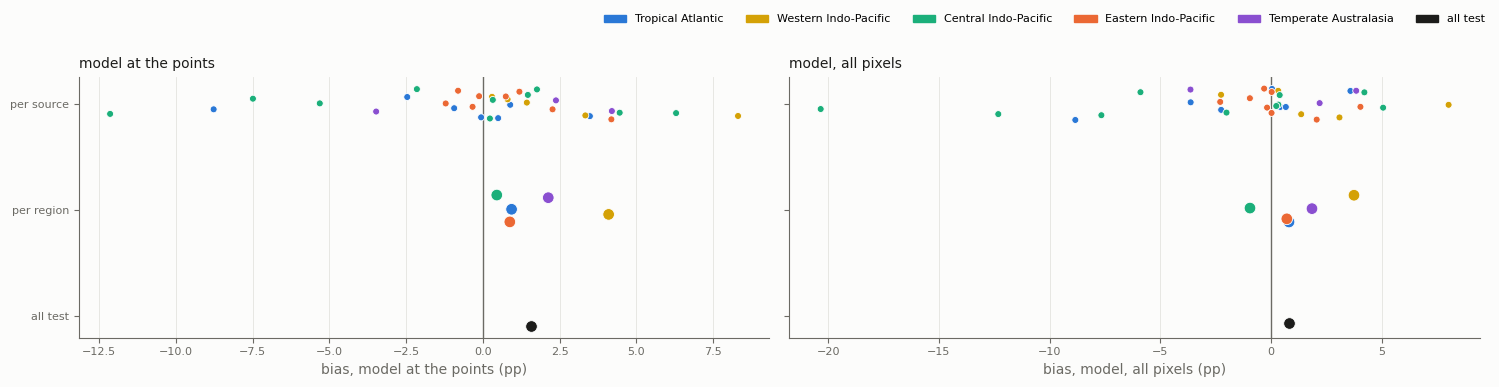

In [20]:
SUMS = {"source": S_SRC, "region": S_REG, "all": S_ALL}
lvl_stats = {}
for lvl, s in SUMS.items():
    for kind, key in (("points", "model_points"), ("all pixels", "model_dense")):
        b = 100 * s[f"bias {key}"]
        sig = ((s[f"bias {key} lo"] > 0) | (s[f"bias {key} hi"] < 0)).sum()
        lvl_stats[(lvl, kind)] = {"groups": len(s), "mean bias (pp)": b.mean(), "mean |bias| (pp)": b.abs().mean(),
                                  "RMS bias (pp)": np.sqrt((b ** 2).mean()), "largest |bias| (pp)": b.abs().max(),
                                  "within ±2 pp": int((b.abs() <= 2).sum()), "within ±5 pp": int((b.abs() <= 5).sum()),
                                  "CI excludes 0": int(sig)}
lvl_stats = pd.DataFrame(lvl_stats)
display(lvl_stats.style.format(lambda v: f"{v:.2f}" if isinstance(v, float) else v))

fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), sharey=True)
for ax, key in zip(axes, ("model_points", "model_dense")):
    for i, (lvl, s) in enumerate(SUMS.items()):
        colors = [REGION_COLOR.get(REGION_OF.get(g, g), INK) for g in s.index]
        ax.scatter(100 * s[f"bias {key}"], i + rng.uniform(-0.15, 0.15, len(s)), c=colors,
                   s=25 if lvl == "source" else 70, edgecolor="white", lw=0.6, zorder=3)
    ax.axvline(0, color=MUTED, lw=1)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(f"bias, {ESTIMATES[key][0]} (pp)")
    ax.set_title(ESTIMATES[key][0])
axes[0].set_yticks(range(3), ["per source", "per region", "all test"])
axes[0].invert_yaxis()
fig.legend(handles=[Patch(color=c, label=r) for r, c in REGION_COLOR.items()] + [Patch(color=INK, label="all test")],
           loc="upper right", ncol=6, fontsize=8, bbox_to_anchor=(1, 1.02))
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()

## 6. Findings
`cbm_cd275000_res768` (step 50k, KL w=0.5, taxv2), predicted at 768 px. Live hard coral = scleractinia and live, in
both the annotations and the prediction. 33 test sources, 34,138 images, 813k points.

**Across all test data the model is close to the ground truth, but slightly high.**
- Ground truth 16.1%. Model 16.9% from all pixels (+0.8 pp, CI [+0.7, +1.0]) and 17.7% at the points (+1.6 pp,
  [+1.5, +1.7]).
- ±5 pp needs 64 images from all pixels, as few as the annotations (74); at the points it needs 134.
- ±2 pp needs 810 images from all pixels and 5,667 at the points, vs 445 for the annotations.
- A 100-image survey's 95% CI contains the ground truth in 94% (pixels) / 90% (points) of surveys, vs 96% for the
  annotations.

**Per region, four of five realms are within ±2 pp.**
- All-pixel bias: Tropical Atlantic +0.8, Western Indo-Pacific +3.8, Central Indo-Pacific −0.9, Eastern
  Indo-Pacific +0.7, Temperate Australasia +1.9 pp. At the points: +0.9, +4.1, +0.5, +0.9, +2.1 pp.
- Western Indo-Pacific is the outlier because of 4721 (+8.0 pp, a third of the realm's images; see below). There, the
  model never reaches ±2 pp, and a 100-image CI contains the ground truth in only 18% of surveys.
- Source biases cancel within realms. In the Central Indo-Pacific, sources run from −20.3 to +5.1 pp (all pixels),
  but the realm is −0.9 pp. 4957, 62% of the realm's images, is +0.3 pp.
- The Eastern Indo-Pacific is consistently good: every source is within −2.3 to +4.0 pp, precision 0.87, recall
  0.91, per-image r 0.94 (pixels).
- ±5 pp needs 63–372 images from all pixels (annotations 33–110). ±2 pp needs 560–1,118, except in the Western
  Indo-Pacific (never).

**Per source, errors are larger and go in both directions.**
- All pixels: mean |bias| 3.4 pp, RMS 5.4 pp, range −20.3 (7116) to +8.0 pp (4721). 13 / 33 sources within ±2 pp,
  26 within ±5 pp.
- At the points: mean |bias| 2.8 pp, RMS 4.1 pp, range −12.1 (6673) to +8.3 pp (4721). 17 within ±2 pp, 27 within
  ±5 pp.

**What drives the large source biases:**
- **Underestimates: coral predicted as no order.**
  - Generic `hard coral` labels, predicted as no order or as coralline algae: 6673 (−12.3 pp, recall 0.19), 2955 (−7.7), 2052 (−5.9).
  - Caribbean *Orbicella* / *Agaricia* in 6494 (−8.8, recall 0.38).
- **7116 (−20.3 pp from all pixels, but +1.5 pp at the points).** The model calls 47.7% of all pixels scleractinia,
  but only 17.4% live hard coral. At the points it calls 40.2% live (ground truth 38.8%). So the live head rejects
  most coral pixels away from the annotated points. Worth checking in the overlays before trusting the dense
  estimate here.
- **Overestimates:**
  - 4721 (+8.0) is mainly a ground-truth problem: bleaching-condition labels (`condition_fully bleached` 3,909,
    `condition_full bleach & partial mortality` 1,726, `condition_paling` 1,377) have no order in the concept table,
    so bleached (live) coral counts as not hard coral.
  - 3606 (+5.1): sponge (1,689 points), corallimorpharians (518) and rock called coral.
  - 2682 (+4.0): turf algae (579). 3656 (+3.9): *Cladiella* soft coral (158).
- **Dead coral is mostly kept out.** Of 31,445 dead-coral points (6 sources), the model calls 5,407 (17%)
  scleractinia and 2,429 (7.7%) live.

**So what.** Global and most regional estimates from all pixels are within ±2 pp of the annotations, with no
annotation needed. Source-level errors reach 8–20 pp, mostly from label vocabularies (generic `hard coral`,
bleaching labels) and from non-coral benthos called coral. They largely cancel in regional averages.

**Caveats.**
- One seed.
- Regions are assigned by hand, and 4 sources have wrong coordinates (see the introduction).
- Pooled sampling weights sources by their image count.
- Ground-truth issues remain: 4721's bleaching labels, generic `hard coral` labels, and `live coral` / `unknown
  coral` labels with no order.
